<a href="https://colab.research.google.com/github/debashisdotchatterjee/Four_Cycle/blob/main/Four_Cycle_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Four-cycle spectral inference | empirical study

Run this notebook in a standard Google Colab CPU runtime using **Runtime → Run all**. It contains the Python source and the original fitted GISSMO XML. The default **paper** profile runs the complete design. The final cell downloads **Four_Cycle_Results.zip**. Keep that ZIP intact for manuscript preparation.

The L-glutamic acid study validates recovery on a *fixed fitted molecule*. The network study measures size and power across *fresh random systems*. The untagged study compares *finite trace moments* with finite and asymptotic theory. These three experiments target different sources of uncertainty.

## 1. Set the run profile and seed
The paper profile uses 2,000 independent hidden systems per size/model/amplitude, 3,000 fixed-molecule replications per budget and 128 independent systems per untagged trace condition. Choose **quick** for a smaller installation check. A fresh directory is created for each run.

In [ ]:
PROFILE = "paper"       # "paper" or "quick"
SEED = 20261124
VERIFY_LIVE_XML = True  # optional byte-for-byte comparison with the current GISSMO XML
DOWNLOAD_ON_FINISH = True

import os
import sys
import tempfile
from pathlib import Path
BASE = Path("/content") if Path("/content").is_dir() else Path.cwd()
CODE_DIR = Path(tempfile.mkdtemp(prefix="four_cycle_code_", dir=BASE))
os.chdir(CODE_DIR)
if PROFILE not in ("paper", "quick"):
    raise ValueError("Choose paper or quick.")
print(f"Profile: {PROFILE}. Seed: {SEED}. Source directory: {CODE_DIR}")

Profile: paper. Seed: 20261124. Source directory: /content/four_cycle_code_u7x_pczp


## 2. Load the fitted spin-system record

The input comes from the [GISSMO L-glutamic acid spin system](https://gissmo.bmrb.io/entry/bmse000037/simulation_1) associated with [BMRB experiment bmse000037](https://doi.org/10.13018/BMSE000037). It provides fitted chemical shifts and couplings. The scalar energy readings generated here are synthetic. The original NMR intensity trace is a different observable.

The snapshot below uses the exact source bytes, including original whitespace. Optional online verification compares the current file with the pinned copy.

In [ ]:
import hashlib
from urllib.request import urlopen
XML_URL = "https://gissmo.bmrb.io/entry/bmse000037/simulation_1/spin_simulation.xml"
XML_HASH = "da2499cf731235ad59dc5b4849cc00973207f720c95d9e792318e0f539bf1192"
xml_snapshot = r"""<spin_simulation>
	<version>2</version>
	<name>L-glutamic-acid</name>
	<ID>bmse000037</ID>
	<SRC name="BMRB" ID="bmse000037"></SRC>
	<InChI>InChI=1S/C5H9NO4/c6-3(5(9)10)1-2-4(7)8/h3H,1-2,6H2,(H,7,8)(H,9,10)/t3-/m0/s1</InChI>
	<comp_db_link>
		<db_link DBname="CAS Registry" Accession_code="10549-13-0"></db_link>
		<db_link DBname="CAS Registry" Accession_code="138-15-8"></db_link>
		<db_link DBname="CAS Registry" Accession_code="138-16-9"></db_link>
		<db_link DBname="CAS Registry" Accession_code="16690-92-9"></db_link>
		<db_link DBname="CAS Registry" Accession_code="19238-49-4"></db_link>
		<db_link DBname="CAS Registry" Accession_code="19473-49-5"></db_link>
		<db_link DBname="CAS Registry" Accession_code="24595-14-0"></db_link>
		<db_link DBname="CAS Registry" Accession_code="55695-80-2"></db_link>
		<db_link DBname="CAS Registry" Accession_code="56-86-0"></db_link>
		<db_link DBname="CAS Registry" Accession_code="6899-05-4"></db_link>
		<db_link DBname="CAS Registry" Accession_code="7558-63-6"></db_link>
	</comp_db_link>
	<mol_file_path>./bmse000037.mol</mol_file_path>
	<experimental_spectrum>
		<type>Bruker</type>
		<root_folder>./1H/</root_folder>
	</experimental_spectrum>
	<field_strength>499.84</field_strength>
	<field_strength_applied_flag>1</field_strength_applied_flag>
	<num_simulation_points>32768</num_simulation_points>
	<num_simulation_points_applied_flag>1</num_simulation_points_applied_flag>
	<path_2D_image>./bmse000037_.jpg</path_2D_image>
	<num_split_matrices>0</num_split_matrices>
	<roi_rmsd>0.00829</roi_rmsd>
	<notes>
		<status>Done</status>
		<note></note>
	</notes>
	<coupling_matrix>
		<label>merged</label>
		<index>1</index>
		<lw>0.740</lw>
		<peak_shape_coefficients>
			<lorentzian>1.000</lorentzian>
			<gaussian>0.000</gaussian>
		</peak_shape_coefficients>
		<water_region>
			<min_ppm>4.6</min_ppm>
			<max_ppm>5</max_ppm>
			<remove_flag>1</remove_flag>
		</water_region>
		<DSS_region>
			<min_ppm>-.1</min_ppm>
			<max_ppm>.1</max_ppm>
			<remove_flag>1</remove_flag>
		</DSS_region>
		<additional_coupling_constants>
		</additional_coupling_constants>
		<spin_names>
			<spin index="1" name="13"></spin>
			<spin index="2" name="14"></spin>
			<spin index="3" name="11"></spin>
			<spin index="4" name="12"></spin>
			<spin index="5" name="15"></spin>
		</spin_names>
		<chemical_shifts_ppm>
			<cs index="1" ppm="2.32906"></cs>
			<cs index="2" ppm="2.34867"></cs>
			<cs index="3" ppm="2.11870"></cs>
			<cs index="4" ppm="2.04950"></cs>
			<cs index="5" ppm="3.74768"></cs>
		</chemical_shifts_ppm>
		<couplings_Hz>
			<coupling from_index="1" to_index="2" value="-15.9396545"></coupling>
			<coupling from_index="1" to_index="3" value="8.8391069"></coupling>
			<coupling from_index="1" to_index="4" value="6.2358859"></coupling>
			<coupling from_index="2" to_index="3" value="6.8022519"></coupling>
			<coupling from_index="2" to_index="4" value="8.9199677"></coupling>
			<coupling from_index="3" to_index="4" value="-14.8676621"></coupling>
			<coupling from_index="3" to_index="5" value="4.7330108"></coupling>
			<coupling from_index="4" to_index="5" value="7.2285919"></coupling>
		</couplings_Hz>
		<peak_list>
		</peak_list>
		<spectrum>
		</spectrum>
	</coupling_matrix>
</spin_simulation>""".encode("utf8")
assert hashlib.sha256(xml_snapshot).hexdigest() == XML_HASH
if VERIFY_LIVE_XML:
    with urlopen(XML_URL, timeout=30) as stream:
        if hashlib.sha256(stream.read()).hexdigest() != XML_HASH:
            raise ValueError("The live record has changed. Compare versions before pooling results.")
(CODE_DIR / "spin_simulation.xml").write_bytes(xml_snapshot)
print("Verified the bundled GISSMO XML.")

Verified the bundled GISSMO XML.


## 3. Inspect the model and experiment code

The following cells write six editable Python modules into this run's source directory. The same modules are included as ordinary Python files in the starter ZIP. All numerical methods work on a CPU. No credentials or Drive mount are needed.

### Spectral measurement and estimators
Diagonalize the 64 possible $16\times16$ tagged sign patterns. Check both conditional spectral laws, the score classes, the order-eight identity and exact binomial intervals.

In [ ]:
%%writefile spectral.py
"""Spectra of four tagged involutions and statistics of energy-only observations."""
from itertools import combinations, product
from math import comb
import numpy as np
import pandas as pd
from scipy.stats import beta, norm

EDGES = tuple(combinations(range(4), 2))
INFO = 41 / 360
CUT = (2 + 1 + 1 / np.sqrt(2)) / 2    # interior of the proved gap
METHODS = ("Endpoint", "Score", "Eighth moment")
NULL_V = {"Endpoint": 511., "Score": 1 / INFO}


def spectrum_from_signs(code):
    """B(S)/2 on the 16 computational states. Bit e of code flags an anticommuting pair."""
    basis = np.arange(16)
    matrix = np.zeros((16, 16))
    for k in range(4):
        phase = np.ones(16)
        for edge, (a, b) in enumerate(EDGES):
            if b == k and (code >> edge) & 1:
                phase *= 1 - 2 * ((basis >> a) & 1)
        matrix[basis ^ (1 << k), basis] = phase / 2
    assert np.array_equal(matrix, matrix.T)
    return np.linalg.eigvalsh(matrix)


def energy_scores(energy):
    """Point estimators use only energies. The ideal discrete atoms have a wide numerical margin."""
    energy = np.asarray(energy)
    z = 4 * energy**2
    def near(x):
        return np.isclose(z, x, rtol=0, atol=1e-7)
    h = np.full(z.shape, -1/3.)
    for value, weight in [(0, 13/45), (2, 1/9), (4, 1/3),
                          (4-2*np.sqrt(3), 0), (4+2*np.sqrt(3), 0),
                          (8, 1), (10, 1), (16, 1)]:
        h[near(value)] = weight
    return np.stack((512*(np.abs(energy) > CUT).astype(float)-1,
                     h / INFO, 16*(energy**8 - 263/32)), axis=-1)


def make_masks():
    """32 equiprobable sign masks, given cross products r_a*t_b; fix the redundant first row sign."""
    masks = []
    for ha, hb, r2, t1, t2 in product((0, 1), repeat=5):
        bits = (ha, t1, t2, r2 ^ t1, r2 ^ t2, hb)
        masks.append(sum(bit << i for i, bit in enumerate(bits)))
    return np.array(masks)


class Spectra:
    def __init__(self):
        self.bank = np.stack([spectrum_from_signs(code) for code in range(64)])
        self.masks = make_masks()
        # Cluster by rounded absolute energy only to merge machine-equal eigenvalues.
        # Use an unrounded mean representative for each even-moment calculation.
        values = np.abs(self.bank).ravel()
        _, bins = np.unique(values.round(10), return_inverse=True)
        bins = bins.ravel()
        self.atoms = np.bincount(bins, weights=values) / np.bincount(bins)
        self.code_laws = np.stack([np.bincount(row, minlength=len(self.atoms))/16
                                   for row in bins.reshape(64, 16)])
        parity = np.array([sum((code >> e) & 1 for e in (1,2,3,4)) % 2 for code in range(64)])
        self.minus = self.code_laws[parity == 1].mean(axis=0)
        self.plus = self.code_laws[parity == 0].mean(axis=0)
        self.scores = energy_scores(self.atoms)
        self.endpoint_index = int(np.flatnonzero(self.atoms > CUT).item())
        for sign, probs in [(-1, self.minus), (1, self.plus)]:
            np.testing.assert_allclose(probs @ self.scores, np.repeat(sign, 3), atol=1e-9)
            np.testing.assert_allclose([probs @ self.atoms**k for k in (2,4,6,8)],
                                       [1, 7/4, 29/8, 263/32+sign/16], atol=1e-10)
        neutral = self.law(0.)
        np.testing.assert_allclose(neutral @ self.scores[:, :2]**2, [511., 1/INFO])
        # Validate the six class multiplicities in the manuscript against the eigenvalues.
        score_labels = (13/45, 1/9, 1/3, 0, 1, -1/3)
        for probs, counts in [(self.minus, (32,64,32,128,0,256)),
                              (self.plus,  (58,80,64,128,54,128))]:
            actual = [512*probs[np.isclose(self.scores[:,1]*INFO, value)].sum()
                      for value in score_labels]
            np.testing.assert_array_equal(actual, counts)
        h = (self.plus-self.minus)/(self.plus+self.minus)
        np.testing.assert_allclose(self.scores[:,1]*INFO, h)

    def law(self, u):
        u = np.asarray(u)[..., None]
        if np.any(np.abs(u) > 1+1e-12):
            raise ValueError("Rectangle average is outside [-1,1].")
        u = u.clip(-1, 1)
        return ((1-u)*self.minus + (1+u)*self.plus)/2


def multinomial_rows(rng, totals, probabilities):
    """One exact multinomial count vector per row. Uses int64 and O(atoms) operations per row."""
    probabilities = np.asarray(probabilities)
    residual = np.broadcast_to(totals, probabilities.shape[:-1]).astype(np.int64).copy()
    counts = np.empty(probabilities.shape, dtype=np.int64)
    tail = probabilities[..., ::-1].cumsum(axis=-1)[..., ::-1]
    for k in range(probabilities.shape[-1]-1):
        p = np.divide(probabilities[...,k], tail[...,k], out=np.zeros_like(tail[...,k]),
                      where=tail[...,k] > 0)
        counts[...,k] = rng.binomial(residual, p.clip(0,1))
        residual -= counts[...,k]
    counts[...,-1] = residual
    return counts


def distinct_rectangle_mean(C):
    """Average over DISTINCT rows and columns. Work on the smaller Gram matrix."""
    C = np.asarray(C, dtype=np.int64)
    if C.shape[-2] > C.shape[-1]:
        C = C.swapaxes(-2, -1)
    m, n = C.shape[-2:]
    g = C @ C.swapaxes(-2, -1)
    off_square = (g*g).sum(axis=(-2,-1)) - m*n*n
    return (off_square - m*(m-1)*n) / (4*comb(m,2)*comb(n,2))


def draw_sign_arrays(rng, shape, model, delta):
    repeats, m, n = shape
    rows = 2*rng.integers(2, size=(repeats, m, 1))-1
    cols = 2*rng.integers(2, size=(repeats, 1, n))-1
    mean = {"Null": 0., "Interaction": delta*rows*cols, "Row": delta*rows}[model]
    return 2*(rng.random(shape) < (1+mean)/2).astype(np.int8)-1


def cp_interval(k, T, alpha=.05):
    k = np.asarray(k)
    lo = np.zeros(k.shape)
    hi = np.ones(k.shape)
    nonzero = k > 0
    nonfull = k < T
    lo[nonzero] = beta.ppf(alpha/2, k[nonzero], T-k[nonzero]+1)
    hi[nonfull] = beta.ppf(1-alpha/2, k[nonfull]+1, T-k[nonfull])
    return 512*lo-1, 512*hi-1


def summarize(values, truth):
    """Independent-replication MCSEs. Variance MCSE uses the fourth central sample moment."""
    x = np.asarray(values, dtype=float)
    r = len(x)
    v = x.var(ddof=1)
    squared_error = (x-truth)**2
    m4 = np.mean((x-x.mean())**4)
    return dict(R=r, mean=x.mean(), bias=x.mean()-truth, bias_mcse=np.sqrt(v/r),
                variance=v, variance_mcse=np.sqrt(max(0., (m4-(r-3)/(r-1)*v*v)/r)),
                rmse=np.sqrt(squared_error.mean()))


def rate_summary(flags):
    k, r = int(np.count_nonzero(flags)), len(flags)
    p = k/r
    # Wilson bounds remain informative if every replication gives the same outcome.
    z = norm.ppf(.975)
    den = 1+z*z/r
    center = (p+z*z/(2*r))/den
    radius = z*np.sqrt(p*(1-p)/r+z*z/(4*r*r))/den
    return dict(rate=p, rate_mcse=np.sqrt(p*(1-p)/r), successes=k,
                rate_lo=max(0., center-radius), rate_hi=min(1., center+radius))

Writing spectral.py


### Fixed-molecule validation
Parse the XML, sample the molecular Pauli terms and generate independent energy shots from physical invariant blocks. A second calculation integrates over all 6,400 ordered choices and 32 masks for fast repeated experiments. The energy estimator receives only the energy record.

In [ ]:
%%writefile molecule.py
"""Generate energy data from deposited NMR terms. Scores receive only binned or raw energies."""
from itertools import product
from pathlib import Path
import hashlib
import xml.etree.ElementTree as ET
import numpy as np
import pandas as pd
from spectral import EDGES, METHODS, energy_scores, cp_interval, summarize, rate_summary

XML_URL = "https://gissmo.bmrb.io/entry/bmse000037/simulation_1/spin_simulation.xml"
XML_SHA = "da2499cf731235ad59dc5b4849cc00973207f720c95d9e792318e0f539bf1192"


def read_spins(xml_path):
    raw = Path(xml_path).read_bytes()
    if hashlib.sha256(raw).hexdigest() != XML_SHA:
        raise ValueError("GISSMO input differs from the pinned record.")
    root = ET.fromstring(raw)
    assert root.findtext('ID') == 'bmse000037' and float(root.findtext('field_strength')) == 499.84
    names = {int(x.get('index')):x.get('name') for x in root.findall('.//spin_names/spin')}
    shifts = sorted((int(x.get('index')),float(x.get('ppm'))) for x in root.findall('.//chemical_shifts_ppm/cs'))
    pairs = [(int(x.get('from_index')),int(x.get('to_index')),float(x.get('value')))
             for x in root.findall('.//couplings_Hz/coupling') if float(x.get('value')) != 0]
    assert len(shifts)==5 and len(pairs)==8
    # (bit-flip mask, Z phase mask, number of Y factors) specifies i^nY X^x Z^z.
    a = np.array([v for _,v in shifts])
    p = (a-a.mean())**2
    p /= p.sum()
    rows = [(0, 1 << (i-1), 0) for i,_ in shifts]
    cols, q, couplings = [], [], []
    for k,l,j in pairs:
        bits = (1 << (k-1)) | (1 << (l-1))
        for op in ['X','Y']:
            cols.append((bits, bits if op=='Y' else 0, 2 if op=='Y' else 0))
            couplings.append((k,l,names[k],names[l],op,j))
            q.append(j*j)
    q = np.asarray(q)/sum(q)
    row_df = pd.DataFrame({'spin_index':[i for i,_ in shifts], 'atom_id':[names[i] for i,_ in shifts],
                           'shift_ppm':a,'row_probability':p})
    col_df = pd.DataFrame(couplings,columns=['spin_k','spin_l','atom_k','atom_l','pauli','coupling_hz'])
    col_df['column_probability'] = q
    return rows, cols, p, q, row_df, col_df


def pair_bit(P,Q):
    return (((P[0] & Q[1]).bit_count() + (P[1] & Q[0]).bit_count()) % 2)


def sign_code(ops):
    return sum(pair_bit(ops[a],ops[b]) << k for k,(a,b) in enumerate(EDGES))


def folded_molecular_law(spec, rows, cols, p, q):
    """Integrate the protocol over 5² x 16² term choices and 32 masks, without using u."""
    original_mass = np.zeros(64)
    for i,ii,j,jj in product(range(len(p)),range(len(p)),range(len(q)),range(len(q))):
        code = sign_code((rows[i],rows[ii],cols[j],cols[jj]))
        original_mass[code] += p[i]*p[ii]*q[j]*q[jj]
    masked_codes = np.arange(64)[:,None] ^ spec.masks
    probs = original_mass @ spec.code_laws[masked_codes].mean(axis=1)
    np.testing.assert_allclose(probs.sum(), 1)
    return probs/probs.sum()


def molecular_shots(rng, spec, rows, cols, p, q, count):
    """Diagonalize a physical orbit of the five-spin + four-auxiliary-qubit Hamiltonian per shot."""
    energies = np.empty(count)
    orbit_bits = np.arange(16)
    for s in range(count):
        i,ii = rng.choice(len(p),2,p=p)
        j,jj = rng.choice(len(q),2,p=q)
        ops = [rows[i],rows[ii],cols[j],cols[jj]]
        mask = int(rng.choice(spec.masks))
        coeff = 2*rng.integers(2,size=4)-1
        tagged = []
        for k,(x,z,ny) in enumerate(ops):
            x |= 1 << (5+k)
            for e,(a,b) in enumerate(EDGES):
                if b==k and mask & (1<<e):
                    z |= 1 << (5+a)
            tagged.append((x,z,ny))
        # Each slot toggles its own auxiliary bit. Every orbit has exactly 16 states.
        # Uniform base state and a uniform eigenvalue in its orbit sample normalized trace.
        basis = np.full(16,rng.integers(512),dtype=int)
        for k,(x,_,_) in enumerate(tagged):
            basis ^= np.where((orbit_bits>>k)&1, x, 0)
        H = np.zeros((16,16))
        for k,(_,z,ny) in enumerate(tagged):
            phase = np.array([(-1)**((int(state)&z).bit_count()+ny//2) for state in basis])
            H[orbit_bits^(1<<k),orbit_bits] = .5*coeff[k]*phase
        assert np.array_equal(H,H.T)
        eig = np.linalg.eigvalsh(H)
        if s < 64:
            np.testing.assert_allclose(eig, spec.bank[sign_code(ops)^mask],atol=1e-12)
        energies[s] = rng.choice(eig)
    return energies


def study_molecule(root, cfg, rng, spec, xml_path):
    rows,cols,p,q,shifts,couplings = read_spins(xml_path)
    shifts.to_csv(root/'data/shifts.csv',index=False)
    couplings.to_csv(root/'data/couplings.csv',index=False)
    probs = folded_molecular_law(spec,rows,cols,p,q)
    energies = molecular_shots(rng,spec,rows,cols,p,q,cfg['physical_shots'])
    pd.DataFrame({'shot':np.arange(1,len(energies)+1),'energy':energies}).to_csv(
        root/'raw/molecular_physical_shots.csv',index=False)
    # The reference is computed independently of the synthetic spectral generator and estimators.
    C = np.array([[1-2*int(i in (k,l)) for k,l in couplings[['spin_k','spin_l']].itertuples(index=False,name=None)]
                  for i in shifts.spin_index])
    K = np.sqrt(p[:,None]*q)*C
    u = np.sum((K @ K.T)**2)
    np.testing.assert_allclose(u, np.sum(np.linalg.svd(K,compute_uv=False)**4))
    np.testing.assert_allclose(probs, spec.law(u),atol=2e-12)
    np.testing.assert_allclose(u, .6244619960496645,atol=2e-12,rtol=0)
    pd.DataFrame({'energy_abs':spec.atoms,'nmr_probability':probs,'nu_minus':spec.minus,
                  'nu_plus':spec.plus,'score_per_shot':spec.scores[:,1]}).to_csv(root/'data/energy_atoms.csv',index=False)
    reference = dict(u=float(u),mean_shift_ppm=float(shifts.shift_ppm.mean()),endpoint_probability=float(probs[spec.endpoint_index]),
                     eighth_moment=float(probs @ spec.atoms**8))
    direct = energy_scores(energies)
    summary, raw, draws = [], {}, cfg['nmr_reps']
    for j,method in enumerate(METHODS):
        pdirect = summarize(direct[:,j],u)
        pdirect.update(method=method,truth=u)
        summary.append(pdirect)
    pd.DataFrame(summary).to_csv(root/'tables/nmr_direct_shots.csv',index=False)
    summary = []
    for T in cfg['nmr_budgets']:
        counts = rng.multinomial(T,probs,size=draws)
        estimates = counts @ spec.scores / T
        lo, hi = cp_interval(counts[:,spec.endpoint_index],T)
        raw['T'+str(T)] = np.column_stack([estimates,lo,hi])
        for j,method in enumerate(METHODS):
            row = summarize(estimates[:,j],u)
            row.update(T=T,method=method,truth=u, theory_variance=float(probs @ (spec.scores[:,j]-u)**2/T))
            if j==0:
                row.update(rate_summary((lo<=u)&(u<=hi)))
            summary.append(row)
    np.savez_compressed(root/'raw/nmr_replicates.npz',**raw)
    results = pd.DataFrame(summary)
    results.to_csv(root/'tables/nmr_performance.csv',index=False)
    return reference,shifts,couplings,C,results

Writing molecule.py


### Hidden arrays
Draw fresh arrays in each condition and distinct rectangles on each array. Use identical energies for the three estimators at each absolute budget. At large budgets use multinomial count vectors. Each empirical size or power estimate includes Monte Carlo uncertainty.

In [ ]:
%%writefile networks.py
"""Distinct rectangles on one hidden network per replication; all methods share its shot record."""
from itertools import combinations
from math import comb
import numpy as np
import pandas as pd
from scipy.stats import norm
from spectral import (EDGES, METHODS, NULL_V, distinct_rectangle_mean, draw_sign_arrays,
                      energy_scores, multinomial_rows, rate_summary, summarize)

MODELS = [('Null',0.)]+[(model,d) for model in ('Interaction','Row') for d in (.25,.5,.75)]


def rectangle_check(rng):
    for m,n in [(2,2),(3,5),(6,3)]:
        C = 2*rng.integers(2,size=(m,n))-1
        exact = np.mean([C[i,j]*C[k,j]*C[i,l]*C[k,l]
                         for i,k in combinations(range(m),2) for j,l in combinations(range(n),2)])
        np.testing.assert_allclose(distinct_rectangle_mean(C),exact)
        signed = C*(2*rng.integers(2,size=(m,1))-1)*(2*rng.integers(2,size=(1,n))-1)
        np.testing.assert_allclose(distinct_rectangle_mean(signed),exact)


def distinct_draw(rng, size, count):
    i = rng.integers(size,size=count)
    j = rng.integers(size-1,size=count)
    return i, j+(j>=i)


def small_diagonalization(root,cfg,rng,spec):
    """Generate rectangles and actual masked sign patterns, then sample their diagonalized spectra."""
    m,n=6,4
    systems=cfg['small_systems']
    T=cfg['small_shots']
    summary, raw = [], {}
    for model,d in [('Null',0.),('Interaction',.5),('Row',.5)]:
        estimates,truths=[],[]
        for _ in range(systems):
            C=draw_sign_arrays(rng,(1,m,n),model,d)[0]
            a=rng.integers(2,size=(m,m))
            b=rng.integers(2,size=(n,n))
            a=np.triu(a,1)+np.triu(a,1).T
            b=np.triu(b,1)+np.triu(b,1).T
            i,ii=distinct_draw(rng,m,T)
            j,jj=distinct_draw(rng,n,T)
            pattern=a[i,ii]+(b[j,jj]<<5)
            for shift,(row,col) in enumerate([(i,j),(i,jj),(ii,j),(ii,jj)],1):
                pattern |= (C[row,col]<0).astype(int)<<shift
            masked=pattern ^ rng.choice(spec.masks,size=T)
            ys=spec.bank[masked,rng.integers(16,size=T)]
            estimates.append(energy_scores(ys).mean(axis=0))
            truths.append(distinct_rectangle_mean(C))
        estimates=np.array(estimates)
        truths=np.asarray(truths)
        raw[model]=np.column_stack((truths,estimates))
        for k,method in enumerate(METHODS):
            record=summarize(estimates[:,k]-truths,0)
            record.update(model=model,delta=d,T=T,method=method,m=m,n=n,
                          estimand='estimation error relative to realized U_C')
            summary.append(record)
    np.savez_compressed(root/'raw/small_tagged.npz',**raw)
    pd.DataFrame(summary).to_csv(root/'tables/small_tagged.csv',index=False)


def study_networks(root,cfg,rng,spec):
    summaries=[]
    R=cfg['graph_reps']
    crit=norm.ppf(.95)
    for n in cfg['network_sizes']:
        for aspect in (1,2):
            m=aspect*n
            L=comb(m,2)*comb(n,2)
            for model,delta in MODELS:
                truth=delta**4
                # Batching bounds memory. All budgets use the same R independently drawn systems.
                parts=[]
                for offset in range(0,R,96):
                    C=draw_sign_arrays(rng,(min(96,R-offset),m,n),model,delta)
                    parts.append(distinct_rectangle_mean(C))
                realized=np.concatenate(parts)
                laws=spec.law(realized)
                arrays={'U_C':realized}
                for design,design_v in NULL_V.items():
                    for multiple in (.1,1.,10.):
                        T=max(1,round(design_v*L*multiple))
                        counts=multinomial_rows(rng,T,laws)
                        est=counts @ spec.scores/T
                        arrays[f'{design}_{multiple:g}_T{T}']=est
                        for k,method in enumerate(METHODS):
                            row=summarize(est[:,k],truth)
                            row.update(model=model,delta=delta,truth=truth,m=m,n=n,L=L,T=T,
                                       budget_for=design,budget_ratio=multiple,method=method,
                                       U_mean=realized.mean(),U_variance=realized.var(ddof=1))
                            if method in NULL_V:
                                v=NULL_V[method]
                                null_var=1/L+(v-1/L)/T
                                row.update(null_variance=null_var,
                                           **rate_summary(est[:,k]>crit*np.sqrt(null_var)))
                            summaries.append(row)
                name=f'network_{m}x{n}_{model}_{delta:g}.npz'
                np.savez_compressed(root/'raw'/name,**arrays)
            print(f'  network grid completed: {m} x {n}',flush=True)
    ans=pd.DataFrame(summaries)
    ans.to_csv(root/'tables/network_performance.csv',index=False)
    return ans


def fixed_system_coverage(root, cfg, rng):
    """Select one independent array per condition and repeat the entire endpoint experiment."""
    from scipy.stats import binom
    from spectral import cp_interval

    rows, fixed, raw = [], {}, {}
    R = cfg['conditional_reps']
    tail_probability = .025
    for n in cfg['network_sizes']:
        for aspect in (1, 2):
            m = aspect*n
            L = comb(m, 2)*comb(n, 2)
            for model, delta in MODELS:
                C = draw_sign_arrays(rng, (1, m, n), model, delta)[0]
                system_key = f'{m}x{n}_{model}_{delta:g}'
                fixed[system_key] = C
                u = float(distinct_rectangle_mean(C))
                p = (1+u)/512
                for design, v in NULL_V.items():
                    for ratio in (.1, 1., 10.):
                        T = max(1, round(ratio*v*L))
                        counts = rng.binomial(T, p, size=R)
                        raw[f'{system_key}_{design}_{ratio:g}_T{T}'] = counts
                        # Invert the two exact one-sided binomial tests. The upper
                        # bound follows by applying the lower quantile to T - count.
                        low = int(binom.ppf(tail_probability, T, p))
                        high = T - int(binom.ppf(tail_probability, T, 1-p))
                        covered = (low <= counts) & (counts <= high)
                        exact = binom.cdf(high, T, p) - binom.cdf(low-1, T, p)
                        # Verify the count-space inversion using explicit beta interval bounds.
                        lo_u, hi_u = cp_interval(counts[:12], T)
                        np.testing.assert_array_equal(covered[:12], (lo_u <= u) & (u <= hi_u))
                        assert .95-1e-8 <= exact <= 1+1e-12
                        rows.append(dict(m=m, n=n, model=model, delta=delta, U_C=u,
                                         endpoint_p=p, T=T, R=R, budget_for=design,
                                         budget_ratio=ratio, min_covered_count=low,
                                         max_covered_count=high, exact_coverage=exact,
                                         **rate_summary(covered)))
    np.savez_compressed(root/'raw/coverage_systems.npz', **fixed)
    np.savez_compressed(root/'raw/coverage_endpoint_counts.npz', **raw)
    frame = pd.DataFrame(rows)
    frame.to_csv(root/'tables/network_conditional_coverage.csv', index=False)
    return frame

Writing networks.py


### Untagged moments
Compute the normalized trace of orders four, six and eight on each realized system by propagating $H^k\vert0\rangle$ to Hamming distance at most four. A separate enumeration of even words gives exact finite expectations and graphon limits. Small dense diagonalizations and exhaustive sign averages validate both routes.

In [ ]:
%%writefile untagged.py
"""Direct finite-system moments from a sparse Pauli trace and an independent pairing benchmark."""
from functools import lru_cache
from itertools import combinations, product
from math import prod
import numpy as np
import pandas as pd
from spectral import draw_sign_arrays, summarize
from networks import MODELS


class TraceLayers:
    """Only bitstrings of Hamming weight <=4 are reachable in H^4|0>. Cache their incidence."""
    def __init__(self,N):
        self.layers=[]
        parent_masks=np.array([0],dtype=np.int64)
        for degree in range(1,5):
            vertices=np.array(list(combinations(range(N),degree)),dtype=int).reshape(-1,degree)
            powers=np.left_shift(np.int64(1),vertices)
            masks=powers.sum(axis=1)
            order=masks.argsort()
            vertices,powers,masks=vertices[order],powers[order],masks[order]
            parents=np.searchsorted(parent_masks,(masks[:,None]^powers))
            self.layers.append((vertices,parents,len(parent_masks)))
            parent_masks=masks

    def moments(self,S,weights):
        # Upward and downward amplitudes are transposes of one another by self-adjointness.
        incidences=[]
        for vertices,parents,parent_size in self.layers:
            factors=weights[vertices].copy()
            for k in range(1,vertices.shape[1]):
                for j in range(k):
                    factors[:,k]*=S[vertices[:,j],vertices[:,k]]
            incidences.append((factors,parents,parent_size))
        amplitudes={0:np.ones(1)}
        output=[]
        for step in range(1,5):
            reached={}
            for degree,amplitude in amplitudes.items():
                factors,parents,_=incidences[degree]
                up=(factors*amplitude[parents]).sum(axis=1)
                reached[degree+1]=reached.get(degree+1,0)+up
                if degree>0:
                    factors,parents,size=incidences[degree-1]
                    down=np.bincount(parents.ravel(),weights=(factors*amplitude[:,None]).ravel(),minlength=size)
                    reached[degree-1]=reached.get(degree-1,0)+down
            amplitudes=reached
            if step>=2:
                output.append(sum(a@a for a in amplitudes.values()))
        return np.array(output)


def pairings(points):
    if not points:
        yield ()
        return
    a,*rest=points
    for b in rest:
        for tail in pairings([x for x in rest if x!=b]):
            yield ((a,b),)+tail


def block_words(k):
    """Distinct equality patterns of length 2k with all multiplicities even."""
    seen=set()
    # Partition the k pairs into equal-index classes via restricted growth strings.
    def patterns(x):
        if len(x)==k:
            yield x
        else:
            for t in range(max(x)+2):
                yield from patterns(x+(t,))
    for paired in pairings(list(range(2*k))):
        for partition in patterns((0,)):
            word=[0]*(2*k)
            for (a,b),s in zip(paired,partition):
                word[a]=word[b]=s
            # pairings are ordered by first endpoint, so the labels already follow first appearance.
            seen.add(tuple(word))
    return sorted(seen)


@lru_cache(None)
def diagram_terms(k):
    """Collect multiplicities of block-typed even words whose sign expectation can be nonzero."""
    from collections import Counter
    terms=Counter()
    for word in block_words(k):
        size=max(word)+1
        edges=[(i,j) for i,j in combinations(range(size),2)
               if sum(word[a]==j and word[b]==i for a in range(len(word)) for b in range(a+1,len(word)))%2]
        degree=[sum(v in edge for edge in edges) for v in range(size)]
        for types in product((0,1),repeat=size):
            if any(types[i]==types[j] for i,j in edges):
                continue  # within-family distinct signs have mean zero
            a=types.count(0)
            ka=sum(types[v]==0 for v in word)//2
            row_ok=all(d%2==0 for v,d in enumerate(degree) if types[v]==0)
            both_ok=all(d%2==0 for d in degree)
            terms[a,size-a,ka,len(edges),row_ok,both_ok]+=1
    return terms


def expected_moments(m,n,model,delta,limit=False):
    """Exact annealed finite trace or its graphon limit. Distinct vertices are sampled without collision."""
    out=[]
    for k in (2,3,4):
        total=0.
        for (a,b,ka,edges,row_ok,both_ok),freq in diagram_terms(k).items():
            if model=='Null' and edges: continue
            if model=='Interaction' and not both_ok: continue
            if model=='Row' and not row_ok: continue
            if limit:
                if a+b!=k: continue
                weight=.5**k
            else:
                fall_m=prod(m-t for t in range(a)) if a<=m else 0
                fall_n=prod(n-t for t in range(b)) if b<=n else 0
                weight=fall_m*fall_n/(2*m)**ka/(2*n)**(k-ka)
            total+=freq*weight*delta**edges
        out.append(total)
    return np.array(out)


def sample_system(rng,m,n,model,d):
    C=draw_sign_arrays(rng,(1,m,n),model,d)[0]
    a=rng.integers(0,2,size=(m+n,m+n))
    a=np.triu(2*a-1,1)
    S=a+a.T+np.eye(m+n,dtype=int)
    S[:m,m:]=C
    S[m:,:m]=C.T
    return S


def trace_checks():
    rng=np.random.default_rng(418)
    # Independent dense matrix validation, including nonuniform family weights.
    for m,n in [(2,2),(3,2)]:
        N=m+n
        S=sample_system(rng,m,n,'Interaction',.5)
        c=np.r_[np.full(m,1/np.sqrt(2*m)),np.full(n,1/np.sqrt(2*n))]
        H=np.zeros((2**N,2**N))
        for state in range(2**N):
            for i in range(N):
                phase=prod(S[j,i] for j in range(i) if state&(1<<j))
                H[state^(1<<i),state]=c[i]*phase
        es=np.linalg.eigvalsh(H)
        np.testing.assert_allclose(TraceLayers(N).moments(S,c),[(es**k).mean() for k in (4,6,8)],atol=1e-10)
    # Independent annealed check: enumerate the full 4-vertex sign space under several kernels.
    m=n=2
    layers=TraceLayers(4)
    c=np.ones(4)/2
    edges=list(combinations(range(4),2))
    moments=[]
    patterns=[]
    for bits in product((-1,1),repeat=6):
        S=np.eye(4,dtype=int)
        for (i,j),s in zip(edges,bits): S[i,j]=S[j,i]=s
        patterns.append(bits)
        moments.append(layers.moments(S,c))
    for model,d in [('Null',0),('Interaction',.5),('Row',.75)]:
        prob=np.zeros(64)
        for tags in product((-1,1),repeat=4):
            means=[(0 if i//2==j//2 else (d*tags[i]*tags[j] if model=='Interaction' else d*tags[i]))
                   for i,j in edges]
            prob+=np.prod((1+np.array(patterns)*means)/2,axis=1)/16
        np.testing.assert_allclose(prob @ moments,expected_moments(2,2,model,d),atol=1e-11)
    for model,d in MODELS:
        M4,M6,M8=expected_moments(2,2,model,d,True)
        np.testing.assert_allclose([M4,M6],[2,5+(3*d*d/8 if model=='Row' else 0)])
        if model!='Row': np.testing.assert_allclose(M8,14+d**4/4)


def study_untagged(root,cfg,rng):
    records=[]
    all_raw={}
    for n in cfg['trace_sizes']:
        for aspect in (1,2):
            m=n*aspect
            op=TraceLayers(m+n)
            c=np.r_[np.full(m,1/np.sqrt(2*m)),np.full(n,1/np.sqrt(2*n))]
            for model,d in MODELS:
                finite=expected_moments(m,n,model,d)
                limit=expected_moments(m,n,model,d,True)
                val=np.stack([op.moments(sample_system(rng,m,n,model,d),c) for _ in range(cfg['trace_reps'])])
                all_raw[f'{m}x{n}_{model}_{d:g}']=val
                for k,order in enumerate((4,6,8)):
                    r=summarize(val[:,k],finite[k])
                    r.update(m=m,n=n,model=model,delta=d,order=order,
                             finite_target=finite[k],limit=limit[k],finite_minus_limit=finite[k]-limit[k])
                    records.append(r)
            print(f'  untagged traces completed: {m} x {n}',flush=True)
    out=pd.DataFrame(records)
    out.to_csv(root/'tables/untagged_moments.csv',index=False)
    np.savez_compressed(root/'raw/untagged_traces.npz',**all_raw)
    return out

Writing untagged.py


### Figure and table specifications
Four figures cover molecular calibration, network inference, finite-size moments and the shot-budget crossover. Each figure is exported as vector PDF and high-resolution PNG. LaTeX tables use booktabs.

In [ ]:
%%writefile presentation.py
"""Publication figures and LaTeX tables derived from the saved replicate summaries."""
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter, MaxNLocator
from spectral import METHODS

COL = {'Endpoint':'#ab5227','Score':'#176586','Eighth moment':'#72549a',
       'Null':'#353f49','Interaction':'#187771','Row':'#ad562e'}
MARK = {'Endpoint':'s','Score':'o','Eighth moment':'^','Null':'o','Interaction':'s','Row':'^'}


def style():
    plt.rcParams.update({'font.family':'DejaVu Sans','font.size':9.5,'axes.titlesize':11,
                         'axes.titleweight':'bold','axes.labelcolor':'#193144','text.color':'#193144',
                         'axes.spines.top':False,'axes.spines.right':False,
                         'axes.edgecolor':'#a8b3bc','axes.axisbelow':True,'grid.color':'#d8dfe4',
                         'grid.linewidth':.6,'pdf.fonttype':42,'ps.fonttype':42,'savefig.facecolor':'white'})


def save(fig,root,name):
    for ext in ['pdf','png']:
        fig.savefig(root/'figures'/f'{name}.{ext}',dpi=260,bbox_inches='tight',pad_inches=.12)
    plt.close(fig)


def molecule_figure(root,shifts,couplings,C,results):
    fig,axes=plt.subplots(1,2,figsize=(10.2,4.15),gridspec_kw={'width_ratios':[1,1.13]})
    fig.subplots_adjust(wspace=.37,bottom=.24,top=.88)
    ax=axes[0]
    ax.imshow(C[:,::2],cmap=ListedColormap(['#c46b36','#d9eaf0']),vmin=-1,vmax=1,aspect='auto')
    names=[f'{a}–{b}' for a,b in couplings.iloc[::2][['atom_k','atom_l']].itertuples(index=False,name=None)]
    ax.set(xticks=range(len(names)),xticklabels=names,yticks=range(5),yticklabels=shifts.atom_id,
           xlabel='Coupled proton pair (atom IDs)',ylabel='Shift proton (atom ID)')
    ax.tick_params(axis='x',labelrotation=48)
    ax.set_title('a   Commutation signs',loc='left')
    for i in range(5):
        for j,v in enumerate(C[i,::2]):
            ax.text(j,i,'−' if v<0 else '+',ha='center',va='center',color='#40250e' if v<0 else '#264c60')
    ax=axes[1]
    for method in METHODS:
        grp=results[results.method==method].sort_values('T')
        ax.loglog(grp['T'],grp.rmse,marker=MARK[method],color=COL[method],label=method,lw=1.6)
        ax.loglog(grp['T'],np.sqrt(grp.theory_variance),ls=':',color=COL[method],lw=1.3)
    ax.set(xlabel='Energy shots per replication',ylabel='Root mean squared error')
    ax.grid(True,which='major')
    ax.set_title('b   Recovery of the molecular reference',loc='left')
    ax.legend(frameon=False,fontsize=8)
    save(fig,root,'01_molecular_calibration')


def network_figure(root,df,focus):
    fig,axes=plt.subplots(2,2,figsize=(10.3,6.8),sharex='col',sharey='col')
    fig.subplots_adjust(wspace=.29,hspace=.32,top=.88,bottom=.14)
    sample=df[(df.budget_for=='Score')&(df.budget_ratio==1)&df.method.isin(('Endpoint','Score'))]
    for row,aspect in enumerate((1,2)):
        sel=sample[sample.m==aspect*sample.n]
        ax=axes[row,0]
        ax.axhline(.05,ls='--',lw=1,color='#687783')
        for method,shift in [('Endpoint',-.05),('Score',.05)]:
            g=sel[(sel.model=='Null')&(sel.method==method)].sort_values('n')
            xx=np.arange(len(g))+shift
            ax.errorbar(xx,g.rate,yerr=[np.maximum(0,g.rate-g.rate_lo),np.maximum(0,g.rate_hi-g.rate)],label=method,
                        color=COL[method],marker=MARK[method],capsize=2,ms=4,lw=1.3)
            ax.set_xticks(range(len(g)),g.n.astype(str))
        ax.set(ylabel='Null rejection probability',xlabel='Number of columns, n')
        ax.set_title(f'{"ac"[row]}   Size · '+('m = n' if row==0 else 'm = 2n'),loc='left')
        ax.yaxis.set_major_formatter(PercentFormatter(1,decimals=1))
        ax.grid(axis='y')
        ax=axes[row,1]
        for method,offset in [('Endpoint',-.013),('Score',.013)]:
            for model,extra,marker,ls in [('Interaction',-.004,'o','-'),('Row',.004,'^','--')]:
                g=sel[(sel.n==focus)&(sel.model==model)&(sel.method==method)].sort_values('delta')
                ax.errorbar(g.delta+offset+extra,g.rate,yerr=[np.maximum(0,g.rate-g.rate_lo),np.maximum(0,g.rate_hi-g.rate)],
                            color=COL[method],marker=marker,ls=ls,ms=4,capsize=2,lw=1.25)
        ax.axhline(.05,color='#687783',ls=':',lw=1)
        ax.set(xticks=[.25,.5,.75],xlabel='Signal amplitude, δ',ylabel='Rejection probability',ylim=(-.035,1.055))
        ax.yaxis.set_major_formatter(PercentFormatter(1,decimals=0))
        ax.grid(axis='y')
        ax.set_title(f'{"bd"[row]}   Power · {aspect*focus} × {focus}',loc='left')
    handles=[Line2D([],[],color=COL[s],lw=3,label=s) for s in METHODS[:2]]
    handles+=[Line2D([],[],color='#4b5154',marker=m,ls=l,label=s) for s,m,l in
              [('Interaction','o','-'),('Row','^','--')]]
    fig.legend(handles=handles,ncol=4,frameon=False,loc='upper center')
    save(fig,root,'02_network_inference')


def budget_figure(root, df, focus):
    """Compare both spectral protocols at their own measurement-to-system crossover."""
    from spectral import NULL_V
    fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.95), sharey=True)
    fig.subplots_adjust(wspace=.18, top=.78, bottom=.17)
    grid = np.geomspace(.085, 12, 180)
    sample = df[(df.model=='Null') & (df.n==focus) & (df.budget_for==df.method)]
    for letter, (method, v), ax in zip('ab', NULL_V.items(), axes):
        ax.axhline(1, color='#8996a0', lw=.9, ls=':')
        ax.axvline(1, color='#b9c5c8', lw=.8, ls=':')
        for color, mark, aspect, offset in [('#176586','o',1,.96),('#ab5227','s',2,1.04)]:
            g = sample[(sample.method==method) & (sample.m==aspect*focus)].sort_values('T')
            L = int(g.L.iloc[0])
            ax.plot(grid, 1+(1-1/(v*L))/grid, color=color, lw=1.4, alpha=.75)
            ax.errorbar(g['T']/(v*L)*offset, L*g.variance, yerr=1.96*L*g.variance_mcse,
                        fmt=mark, ms=4.3, capsize=3, color=color)
        ax.set(xscale='log', yscale='log', xlabel=r'Shot budget $T/(vL)$',
               xticks=[.1,1,10], xticklabels=['0.1','1','10'])
        ax.set_title(f'{letter}   {method}',loc='left')
        ax.grid(axis='y',which='major')
    axes[0].set_ylabel(r'Scaled null variance $L\,\mathrm{Var}$')
    handles=[Line2D([],[],color=c,marker=mk,label=f'{m} × {focus}') for c,mk,m in
             [('#176586','o',focus),('#ab5227','s',2*focus)]]
    fig.legend(handles=handles,ncol=2,frameon=False,loc='upper center')
    save(fig,root,'04_shot_budget')


def trace_figure(root,df):
    fig,axes=plt.subplots(1,3,figsize=(11.2,3.85))
    fig.subplots_adjust(wspace=.35,bottom=.16,top=.77)
    sel=df[(df.m==df.n)&((df.delta==0)|(df.delta==.75))]
    for ax,(letter,order) in zip(axes,zip('abc',(4,6,8))):
        for model,shift in [('Null',-.10),('Interaction',0),('Row',.10)]:
            g=sel[(sel.model==model)&(sel.order==order)].sort_values('n')
            ax.plot(g.n,g.finite_target,color=COL[model],lw=1.25)
            ax.errorbar(g.n+shift,g['mean'],yerr=1.96*g.bias_mcse,color=COL[model],marker=MARK[model],
                        ls='none',ms=4,capsize=2)
            ax.axhline(g.limit.iloc[0],color=COL[model],ls=':',lw=1.15)
        ax.set(xticks=sorted(sel.n.unique()),xlabel='Terms per family, n',ylabel=f'Energy moment of order {order}')
        ax.set_title(f'{letter}   Order {order}',loc='left')
        ax.grid(axis='y')
        ax.yaxis.set_major_locator(MaxNLocator(5))
    handles=[Line2D([],[],color=COL[s],marker=MARK[s],label=s) for s in ['Null','Interaction','Row']]
    fig.legend(handles=handles,loc='upper center',ncol=3,frameon=False)
    save(fig,root,'03_untagged_moments')


def latex_table(root,name,caption,columns,rows):
    """Headers/cells are trusted local TeX strings. The generated fragments require booktabs."""
    align='l'+'r'*(len(columns)-1)
    lines=[r'\begin{table}[htbp]',r'\centering',r'\small',r'\caption{'+caption+'}',
           r'\label{tab:'+name+'}',r'\begin{tabular}{'+align+'}',r'\toprule',
           ' & '.join(columns)+r' \\',r'\midrule']
    lines+=[' & '.join(row)+r' \\' for row in rows]
    lines += [r'\bottomrule',r'\end{tabular}',r'\end{table}']
    (root/'tables'/(name+'.tex')).write_text('\n'.join(lines)+'\n')


def render(root,cfg,ref,shifts,couplings,C,molecule,network,traces,conditional):
    style()
    focus=cfg['network_sizes'][len(cfg['network_sizes'])//2]
    molecule_figure(root,shifts,couplings,C,molecule)
    network_figure(root,network,focus)
    trace_figure(root,traces)
    budget_figure(root,network,focus)
    rows=[]
    for a in molecule.itertuples():
        cov=f'{a.rate:.3f} ({a.rate_mcse:.3f})' if np.isfinite(a.rate) else '---'
        rows.append([str(a.T),a.method,f'{a.bias:.3g} ({a.bias_mcse:.2g})',f'{a.variance:.3g}',
                     f'{a.theory_variance:.3g}',cov])
    latex_table(root,'nmr_recovery',
                r'Molecular recovery over independent synthetic experiments. Parentheses give Monte Carlo standard errors. Coverage refers to the exact equal-tailed 95\% endpoint interval.',
                ['$T$','Estimator','Bias (MCSE)','Variance','Exact variance','Coverage (MCSE)'],rows)
    subset=network[(network.n==focus)&(network.budget_for=='Score')&(network.budget_ratio==1)]
    rows=[]
    for (m,model,d),g in subset.groupby(['m','model','delta'],sort=False):
        by=g.set_index('method')
        cells=[f'{m} $\\times$ {focus}',model,f'{d:g}',f'{int(g["T"].iloc[0]):,}']
        for method in METHODS[:2]:
            a=by.loc[method]
            cells.append(f'{a.rate:.3f} ({a.rate_mcse:.3f})')
        rows.append(cells)
    latex_table(root,'graphon_test',
                r'One-sided 5\% test on independent hidden arrays. Both estimators use identical energy records at $T=\mathrm{round}((360/41)L)$. Parentheses give Monte Carlo standard errors.',
                ['Array','Model',r'$\delta$','$T$','Endpoint','Score'],rows)
    rows=[]
    n=max(cfg['trace_sizes'])
    for a in traces[(traces.m==n)&(traces.n==n)&((traces.delta==0)|(traces.delta==.75))].itertuples():
        rows.append([a.model,str(a.order),f'{a.mean:.4f} ({a.bias_mcse:.4f})',f'{a.finite_target:.4f}',f'{a.limit:.4f}'])
    latex_table(root,'spectral_moments',
                f'Untagged energy moments for a {n}-by-{n} system. Alternative amplitude is 0.75. The empirical mean and its Monte Carlo standard error are computed across independent systems.',
                ['Model','Order','Empirical (MCSE)','Exact finite mean','Limit'],rows)
    fixed=conditional[(conditional.m==focus)&(conditional.n==focus)&
                      (conditional.budget_for=='Score')&(conditional.budget_ratio==1)]
    rows=[[a.model,f'{a.delta:g}',f'{a.U_C:.5f}',str(a.T),f'{a.rate:.3f} ({a.rate_mcse:.3f})',
           f'{a.exact_coverage:.4f}'] for a in fixed.itertuples()]
    latex_table(root,'fixed_array_coverage',
                f'Conditional coverage of the 95\\% endpoint interval on a fixed {focus}-by-{focus} array per model and amplitude. Each row uses {cfg["conditional_reps"]} independent repetitions. The final column sums the binomial mass over all counts whose intervals cover the realized rectangle mean.',
                ['Model',r'$\delta$',r'$U_C$','$T$','Coverage (MCSE)','Exact coverage'],rows)
    small=pd.read_csv(root/'tables/small_tagged.csv')
    rows=[[a.model,a.method,str(a.T),f'{a.bias:.3g} ({a.bias_mcse:.2g})',f'{a.rmse:.3g}'] for a in small.itertuples()]
    latex_table(root,'small_spectra','Direct small-array spectral experiment. Errors are relative to the realized distinct-rectangle average.',
                ['Model','Estimator','$T$','Bias (MCSE)','RMSE'],rows)


CAPTIONS = """# Figure captions

1. **Molecular calibration.** Left: each cell gives the sign for a shift operator and a coupled pair, identified by GISSMO proton atom IDs. XX and YY have the same cross sign, so each pair is shown once. Right: empirical RMSE (symbols and solid lines) and the exact square-root variance (dotted lines) at each fixed-system shot budget. Dotted and solid curves may overlap.
2. **Hidden-array inference.** Left: one-sided rejection probability under the null at nominal 5%. Right: power on the indicated array. Each point uses a fresh-system ensemble. Both estimators receive the same energies and absolute shot budget, T = round((360/41)L). Horizontal marker offsets are for legibility. Bars give 95% Wilson intervals for Monte Carlo rejection probabilities. The row and interaction alternatives are related by column-sign switching, so their population cycle signal and cycle-statistic law coincide at a given amplitude.
3. **Untagged spectral moments.** Balanced arrays under the null and two alternatives at amplitude 0.75. Symbols give empirical means across independent systems; bars are 1.96 Monte Carlo standard errors. Solid lines connect exact finite ensemble means at the simulated sizes. Dotted lines mark the graphon limits. Some theoretical curves coincide. The row-only kernel has nonzero row degrees; its eighth-order benchmark uses the full crossing formula.
4. **Shot budget and null variance.** Symbols give the empirical between-replication variance multiplied by the number L of distinct rectangles, for both shapes at the central n. Bars are 1.96 plug-in Monte Carlo standard errors. Curves give the exact variance using each array's L and the estimator-specific null constant v. The two theoretical curves nearly coincide. The horizontal dotted line marks the hidden-array variance after scaling. The vertical line marks T = vL. Horizontal symbol offsets distinguish the two shapes.
"""

Writing presentation.py


### Profiles, independent random streams and output checks
The runner saves seeds, versions, raw replicates, inputs, figure captions, tables and source code before checking the results archive.

In [ ]:
%%writefile run_study.py
"""Run the full empirical study or its small smoke profile. Python 3.10+."""
import argparse
import hashlib
import json
import platform
import shutil
import tempfile
import time
import zipfile
from datetime import datetime, timezone
from pathlib import Path
from importlib.metadata import version
import numpy as np
from threadpoolctl import threadpool_limits
from spectral import Spectra, METHODS
from molecule import study_molecule, XML_URL, XML_SHA
from networks import study_networks, small_diagonalization, rectangle_check, fixed_system_coverage
from untagged import study_untagged, trace_checks
from presentation import render, CAPTIONS

HERE=Path(__file__).resolve().parent
SCRIPTS=('spectral.py','molecule.py','networks.py','untagged.py','presentation.py','run_study.py')
SETTINGS={
    'paper': dict(network_sizes=[8,16,32],graph_reps=2000,conditional_reps=2000,nmr_reps=3000,
                  nmr_budgets=[2000,10000,50000,200000],physical_shots=2048,
                  small_systems=350,small_shots=2048,trace_sizes=[3,6,9],trace_reps=128),
    'quick': dict(network_sizes=[6,10],graph_reps=160,conditional_reps=200,nmr_reps=200,
                  nmr_budgets=[1000,5000,20000],physical_shots=128,
                  small_systems=30,small_shots=256,trace_sizes=[3,5],trace_reps=12),
}

RAW_GUIDE="""# Contents of the results archive

## Inputs and estimands
- data/spin_simulation.xml is the archived GISSMO fitted input. data/shifts.csv and data/couplings.csv retain both atom IDs and selection weights. The archived NMR signal has not been interpreted as a tagged energy sample.
- data/reference.json records the reference from the weighted sign matrix. data/energy_atoms.csv records the molecular energy law obtained independently from fitted terms, masks and exact finite spectra. nu_minus and nu_plus are conditional universal laws of the absolute energy.
- The molecular selection draws with replacement. The graphon selection draws distinct rows and distinct columns. U_C denotes the signed average on a realized network; the population target is zero under the null and delta^4 for either alternative. All inference uses untruncated point estimates.

## Replication data
- raw/molecular_physical_shots.csv contains independently simulated signed energy observations from explicit physical Hamiltonian blocks on the fitted five-spin system and four auxiliary qubits. Each observation redraws term indices, auxiliary masks, coefficient signs and the state. Only energy reaches the estimator.
- raw/nmr_replicates.npz has one matrix per T. Columns are endpoint estimate, score estimate, eighth-moment estimate, lower and upper binomial confidence bounds for u (unclipped). Intersecting the interval with the feasible parameter space has identical coverage of the true reference.
- raw/small_tagged.npz has one matrix per model. Columns are realized U_C, endpoint, score, eighth-moment estimates. Four-slot 16-dimensional spectra are diagonalized once for every sign pattern; each shot then draws a rectangle, random mask and eigenvalue.
- raw/network_*.npz has one file per size/model/amplitude. U_C is a vector of independent system truths. Other keys encode the design estimator, multiplier and absolute T; each R-by-3 matrix uses the same three estimator columns as above. All methods at a given budget use the same observations. Budgets share systems but use independent shot records conditionally on them. Each scenario uses new systems. Network p-values or intervals should not be calculated from iid energy shots unconditionally.
- raw/coverage_systems.npz contains one independently drawn and then fixed sign array for each condition. raw/coverage_endpoint_counts.npz contains the independent repeated counts on that same array at each budget. tables/network_conditional_coverage.csv gives their coverage of U_C and the exact binomial acceptance probability for that array.
- raw/untagged_traces.npz stores R-by-3 arrays of exact conditional trace moments of orders 4, 6 and 8. The uncertainty here is between simulated systems. Calculations exploit the signed Pauli representation and contain no finite-shot noise.

## Tables and figures
- tables/nmr_performance.csv: each row compares an estimator to the fixed molecular reference. Theory variance accounts for the molecular energy distribution at its actual reference. Coverage is computed only for the exact Clopper–Pearson endpoint interval.
- tables/network_performance.csv: every array, model, amplitude, T and estimator. Bias is relative to the population target. Variance is empirical across independent systems and includes both noise sources. null_variance is the exact null variance at that size and T, also shown as the benchmark on alternative rows. rate is null size or alternative power at one-sided nominal 5%. The eighth-moment method has no proposed rejection rule and its test columns are empty.
- tables/small_tagged.csv measures error relative to the realized network. tables/nmr_direct_shots.csv summarizes single-shot values; its variance refers to per-shot variation. tables/untagged_moments.csv compares numerical trace means to exact finite ensemble expectations and limits. For the row-only alternative the full pairing formula determines the eighth moment.
- bias_mcse is the Monte Carlo standard error of the reported bias or trace mean. variance_mcse is a plug-in fourth-central-moment approximation. rate_mcse is the binomial Monte Carlo standard error; rate_lo and rate_hi give Wilson 95% Monte Carlo uncertainty for rejection or empirical coverage. These quantify simulation precision.
- figures/ includes vector PDF and 260 dpi PNG versions. Captions are in figures/CAPTIONS.md. tables/*.tex are standalone table environments for a LaTeX manuscript using the booktabs package. The CSVs contain all numerical values.
- config.json, environment.json, SHA256SUMS.txt and code/ provide the seed, simulation settings, runtime versions, file checksums and the exact Python source. From code/: python run_study.py --profile paper --seed 20261124 --xml ../data/spin_simulation.xml (adjust profile/seed to match config.json).
"""


def json_file(path,obj):
    path.write_text(json.dumps(obj,indent=2,allow_nan=False)+'\n',encoding='utf8')


def sha(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()


def run(profile='paper',seed=20261124,output_parent=None,xml_path=None):
    start=time.monotonic()
    cfg=dict(SETTINGS[profile],profile=profile,seed=int(seed))
    parent=Path(output_parent or Path.cwd()).resolve()
    parent.mkdir(parents=True,exist_ok=True)
    workspace=Path(tempfile.mkdtemp(prefix='four_cycle_run_',dir=parent))
    root=workspace/'Four_Cycle_Results'
    for sub in ('data','raw','tables','figures','code'):
        (root/sub).mkdir(parents=True,exist_ok=True)
    source=Path(xml_path) if xml_path is not None else HERE/'spin_simulation.xml'
    shutil.copyfile(source,root/'data/spin_simulation.xml')
    for name in SCRIPTS:
        shutil.copyfile(HERE/name,root/'code'/name)
    json_file(root/'config.json',cfg)
    rngs=[np.random.default_rng(s) for s in np.random.SeedSequence(seed).spawn(6)]
    # Separate streams for checks, molecule, direct small systems, large networks, traces, and fixed-array coverage.
    with threadpool_limits(limits=1):
        spec=Spectra()
        rectangle_check(rngs[0])
        trace_checks()
        print('Four-slot spectral laws, distinct rectangles and finite trace benchmarks verified.',flush=True)
        ref,shifts,couplings,C,molecular=study_molecule(root,cfg,rngs[1],spec,source)
        ref.update(record='bmse000037',dataset_doi='10.13018/BMSE000037',xml_source=XML_URL,
                   xml_sha256=XML_SHA,field_mhz=499.84)
        json_file(root/'data/reference.json',ref)
        print(f'Molecular reference {ref["u"]:.9f}; direct spectra and coverage completed.',flush=True)
        small_diagonalization(root,cfg,rngs[2],spec)
        networks=study_networks(root,cfg,rngs[3],spec)
        traces=study_untagged(root,cfg,rngs[4])
        conditional=fixed_system_coverage(root,cfg,rngs[5])
        render(root,cfg,ref,shifts,couplings,C,molecular,networks,traces,conditional)
    assert len(conditional)==len(cfg['network_sizes'])*2*7*6
    expected_graph_rows=len(cfg['network_sizes'])*2*7*6*len(METHODS)
    assert len(networks)==expected_graph_rows and np.isfinite(networks.bias).all()
    assert len(traces)==len(cfg['trace_sizes'])*2*7*3 and np.isfinite(traces['mean']).all()
    assert all((root/'figures'/(stem+'.pdf')).stat().st_size>1000 for stem in
               ['01_molecular_calibration','02_network_inference','03_untagged_moments','04_shot_budget'])
    (root/'RESULTS_README.md').write_text(RAW_GUIDE,encoding='utf8')
    (root/'figures/CAPTIONS.md').write_text(CAPTIONS,encoding='utf8')
    json_file(root/'environment.json',dict(completed_utc=datetime.now(timezone.utc).isoformat(),
              python=platform.python_version(),platform=platform.platform(),
              versions={k:version(k) for k in ['numpy','pandas','scipy','matplotlib','threadpoolctl']},
              elapsed_seconds=round(time.monotonic()-start,2),independent_streams=6,
              network_summary_rows=len(networks),trace_summary_rows=len(traces),fixed_coverage_rows=len(conditional)))
    files=sorted(p for p in root.rglob('*') if p.is_file())
    checksum_file=root/'SHA256SUMS.txt'
    checksum_file.write_text(''.join(f'{sha(f)}  {f.relative_to(root).as_posix()}\n' for f in files))
    archive=workspace/('Four_Cycle_Results.zip' if profile=='paper' else 'Four_Cycle_Results_QUICK.zip')
    with zipfile.ZipFile(archive,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=4) as z:
        for f in files+[checksum_file]:
            z.write(f,f.relative_to(root))
    with zipfile.ZipFile(archive) as z:
        if z.testzip() is not None: raise IOError('ZIP verification failed')
    print(f'Completed {profile} profile in {time.monotonic()-start:.1f} seconds. Results: {archive}',flush=True)
    return root,archive


if __name__=='__main__':
    parser=argparse.ArgumentParser(description=__doc__)
    parser.add_argument('--profile',choices=SETTINGS,default='paper')
    parser.add_argument('--seed',type=int,default=20261124)
    parser.add_argument('--output',type=Path,default=None)
    parser.add_argument('--xml',type=Path,default=None)
    args=parser.parse_args()
    run(args.profile,args.seed,args.output,args.xml)

Writing run_study.py


## 4. Run all experiments

The graphon grid uses $m=n$ and $m=2n$, three signal amplitudes and all six budgets from the manuscript. Budgets are exact 64-bit integers. Sampling a count vector avoids allocating billions of shot-level records. In the untagged comparison each system's trace is evaluated up to floating-point precision.

In [ ]:
import importlib
sys.path.insert(0, str(CODE_DIR))
for name in ("run_study", "presentation", "untagged", "networks", "molecule", "spectral"):
    sys.modules.pop(name, None)
study = importlib.import_module("run_study")
RESULTS, ARCHIVE = study.run(profile=PROFILE, seed=SEED, output_parent=BASE)
os.chdir(BASE)

Four-slot spectral laws, distinct rectangles and finite trace benchmarks verified.
Molecular reference 0.624461996; direct spectra and coverage completed.
  network grid completed: 8 x 8
  network grid completed: 16 x 8
  network grid completed: 16 x 16
  network grid completed: 32 x 16
  network grid completed: 32 x 32
  network grid completed: 64 x 32
  untagged traces completed: 3 x 3
  untagged traces completed: 6 x 3
  untagged traces completed: 6 x 6
  untagged traces completed: 12 x 6
  untagged traces completed: 9 x 9
  untagged traces completed: 18 x 9
Completed paper profile in 20.9 seconds. Results: /content/four_cycle_run_e2v4i5pk/Four_Cycle_Results.zip


## 5. Review the results

### Molecular calibration
Solid lines show empirical RMSE and dotted lines show exact standard deviations. The reference comes from the archived fitted matrix. Coverage is evaluated for the exact endpoint binomial interval.

Reference u = 0.624461996. Predicted endpoint probability = 0.00317278.


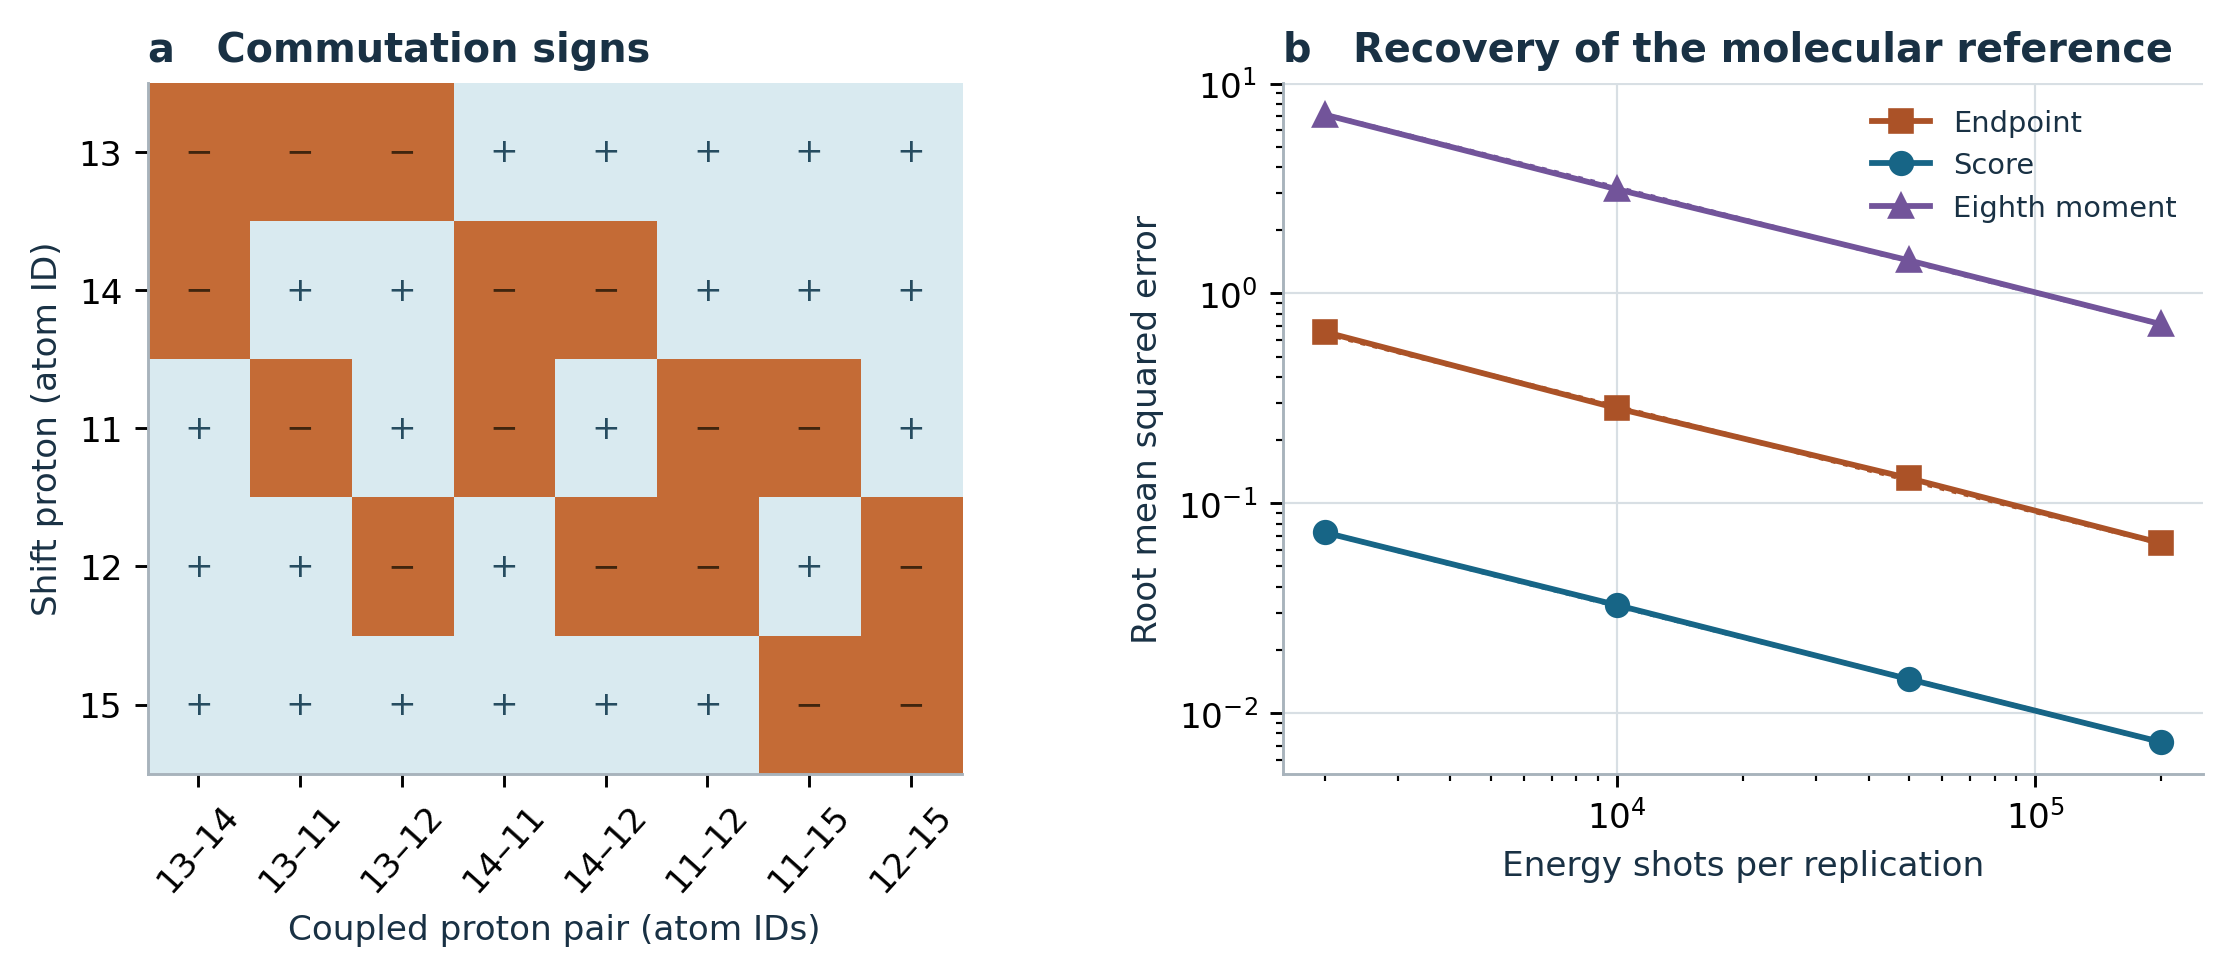

,T,method,bias,bias_mcse,variance,theory_variance,rmse,endpoint_CI_coverage,coverage_MCSE
0,2000,Endpoint,-0.01789,0.01196,0.42934,0.41454,0.65537,0.97400,0.00291
1,2000,Score,-0.00073,0.00133,0.00527,0.00527,0.07259,NaN,NaN
2,2000,Eighth moment,-0.22967,0.12977,50.52283,50.73259,7.11047,NaN,NaN
3,10000,Endpoint,-0.00458,0.00518,0.08037,0.08291,0.28349,0.96233,0.00348
4,10000,Score,-0.00007,0.00060,0.00107,0.00105,0.03270,NaN,NaN
5,10000,Eighth moment,-0.02012,0.05724,9.82852,10.14652,3.13459,NaN,NaN
6,50000,Endpoint,0.00159,0.00240,0.01729,0.01658,0.13148,0.95400,0.00382
7,50000,Score,-0.00031,0.00026,0.00021,0.00021,0.01448,NaN,NaN
8,50000,Eighth moment,0.00934,0.02620,2.05899,2.02930,1.43471,NaN,NaN
9,200000,Endpoint,0.00058,0.00118,0.00417,0.00415,0.06457,0.95133,0.00393


In [ ]:
import json
import pandas as pd
from IPython.display import Image, FileLink, display
reference = json.loads((RESULTS / "data/reference.json").read_text())
print(f"Reference u = {reference['u']:.9f}. Predicted endpoint probability = {reference['endpoint_probability']:.8f}.")
display(Image(filename=str(RESULTS / "figures/01_molecular_calibration.png"), width=930))
molecular = pd.read_csv(RESULTS / "tables/nmr_performance.csv")
display(molecular[["T","method","bias","bias_mcse","variance","theory_variance","rmse","rate","rate_mcse"]]
        .rename(columns={"rate":"endpoint_CI_coverage","rate_mcse":"coverage_MCSE"}).round(5))

### Null size and alternative power
The figure compares both tests at the same absolute budget, $T=\mathrm{round}((360/41)L)$. The 95% Wilson bars describe Monte Carlo uncertainty in each rejection probability. The full CSV includes the other budgets. A second experiment holds one randomly drawn array per condition fixed across all repeated shot experiments and compares interval coverage with the exact binomial probability. The two alternatives have the same cycle-statistic law at a given amplitude, although their untagged moments can differ.

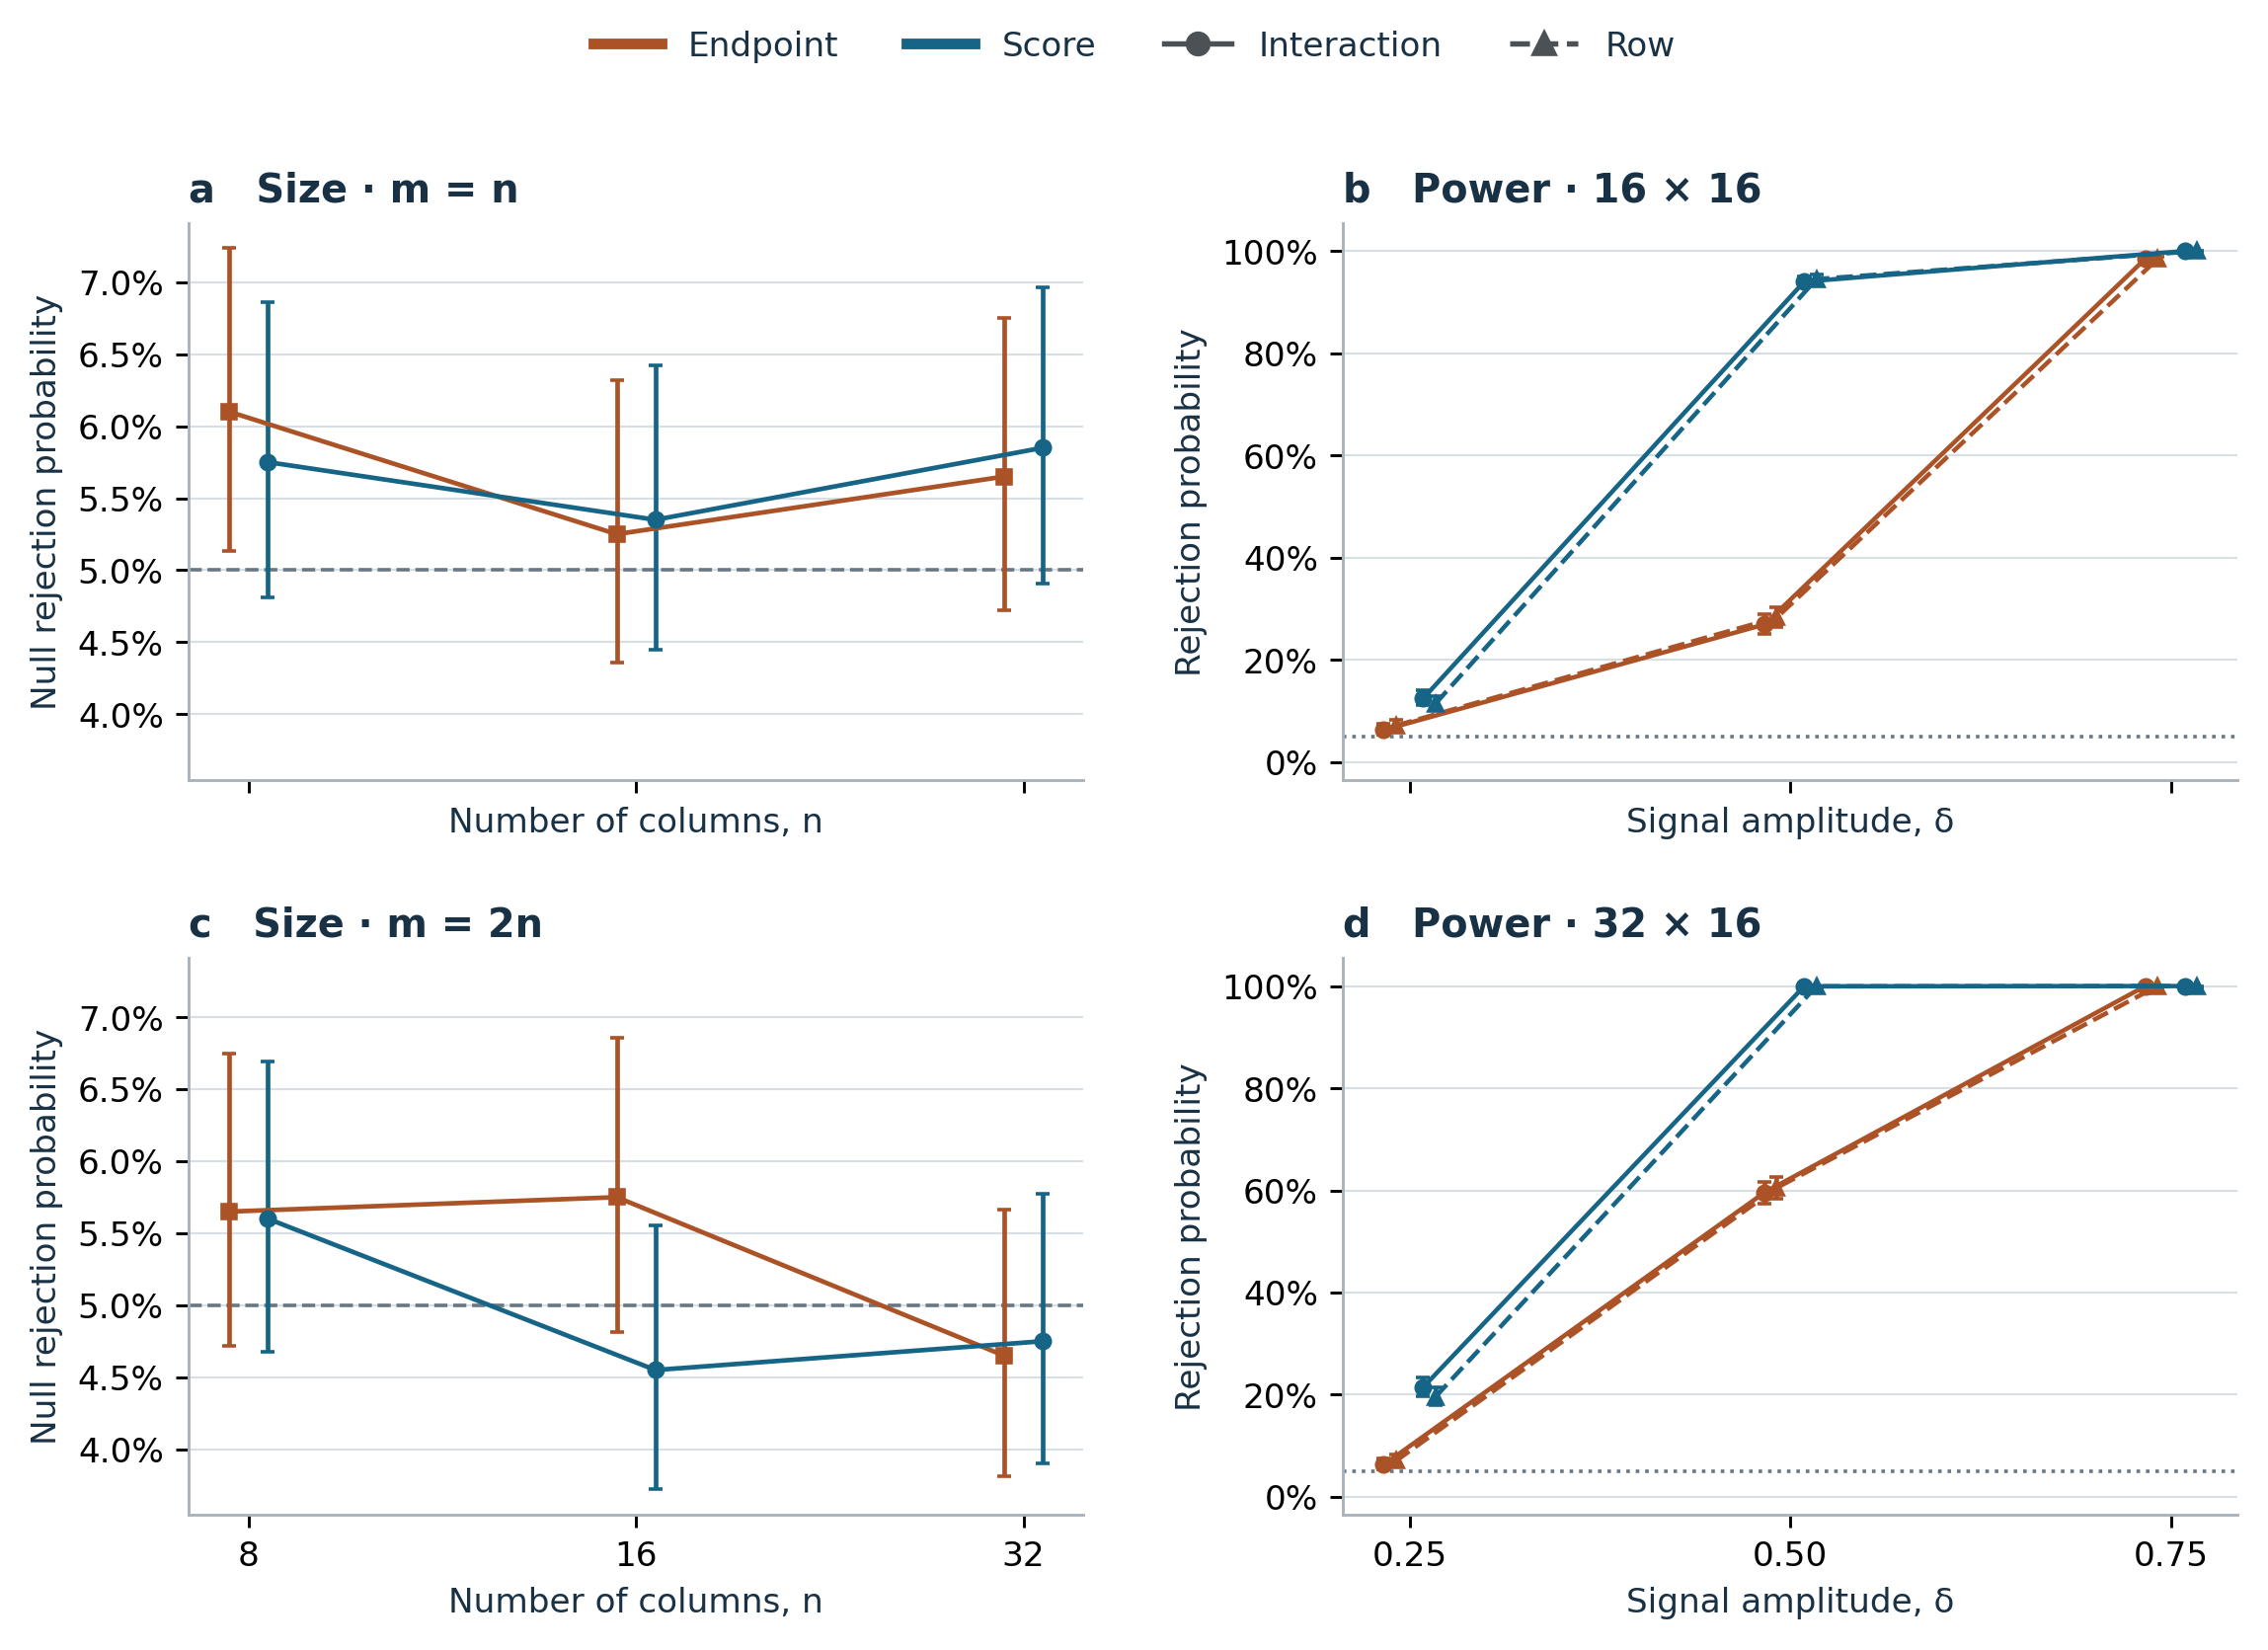

,model,delta,T,method,truth,bias,bias_mcse,variance,rate,rate_mcse
264,Null,0.00,126439,Endpoint,0.00000,-0.00020,0.00141,0.00396,0.0525,0.00499
265,Null,0.00,126439,Score,0.00000,-0.00016,0.00026,0.00014,0.0535,0.00503
282,Interaction,0.25,126439,Endpoint,0.00391,0.00010,0.00143,0.00409,0.0625,0.00541
283,Interaction,0.25,126439,Score,0.00391,0.00039,0.00029,0.00017,0.1245,0.00738
300,Interaction,0.50,126439,Endpoint,0.06250,-0.00309,0.00161,0.00520,0.2690,0.00992
301,Interaction,0.50,126439,Score,0.06250,-0.00020,0.00070,0.00099,0.9400,0.00531
318,Interaction,0.75,126439,Endpoint,0.31641,0.00004,0.00231,0.01068,0.9850,0.00272
319,Interaction,0.75,126439,Score,0.31641,-0.00179,0.00161,0.00517,1.0000,0.00000
336,Row,0.25,126439,Endpoint,0.00391,0.00109,0.00146,0.00428,0.0710,0.00574
337,Row,0.25,126439,Score,0.00391,0.00036,0.00028,0.00016,0.1140,0.00711


In [ ]:
display(Image(filename=str(RESULTS / "figures/02_network_inference.png"), width=930))
grid = pd.read_csv(RESULTS / "tables/network_performance.csv")
focus = sorted(grid.n.unique())[len(grid.n.unique())//2]
view = grid[(grid.n == focus) & (grid.m == focus) & (grid.budget_for == "Score")
            & (grid.budget_ratio == 1) & (grid.method != "Eighth moment")]
display(view[["model","delta","T","method","truth","bias","bias_mcse","variance","rate","rate_mcse"]].round(5))

### Shot budget and null variance
Each estimator uses its own null variance constant $v$. At small $T/(vL)$ the energy measurement contributes most of the variance. At large $T/(vL)$ variation across hidden arrays dominates. The curves show the exact null variance and the symbols give its empirical estimate.

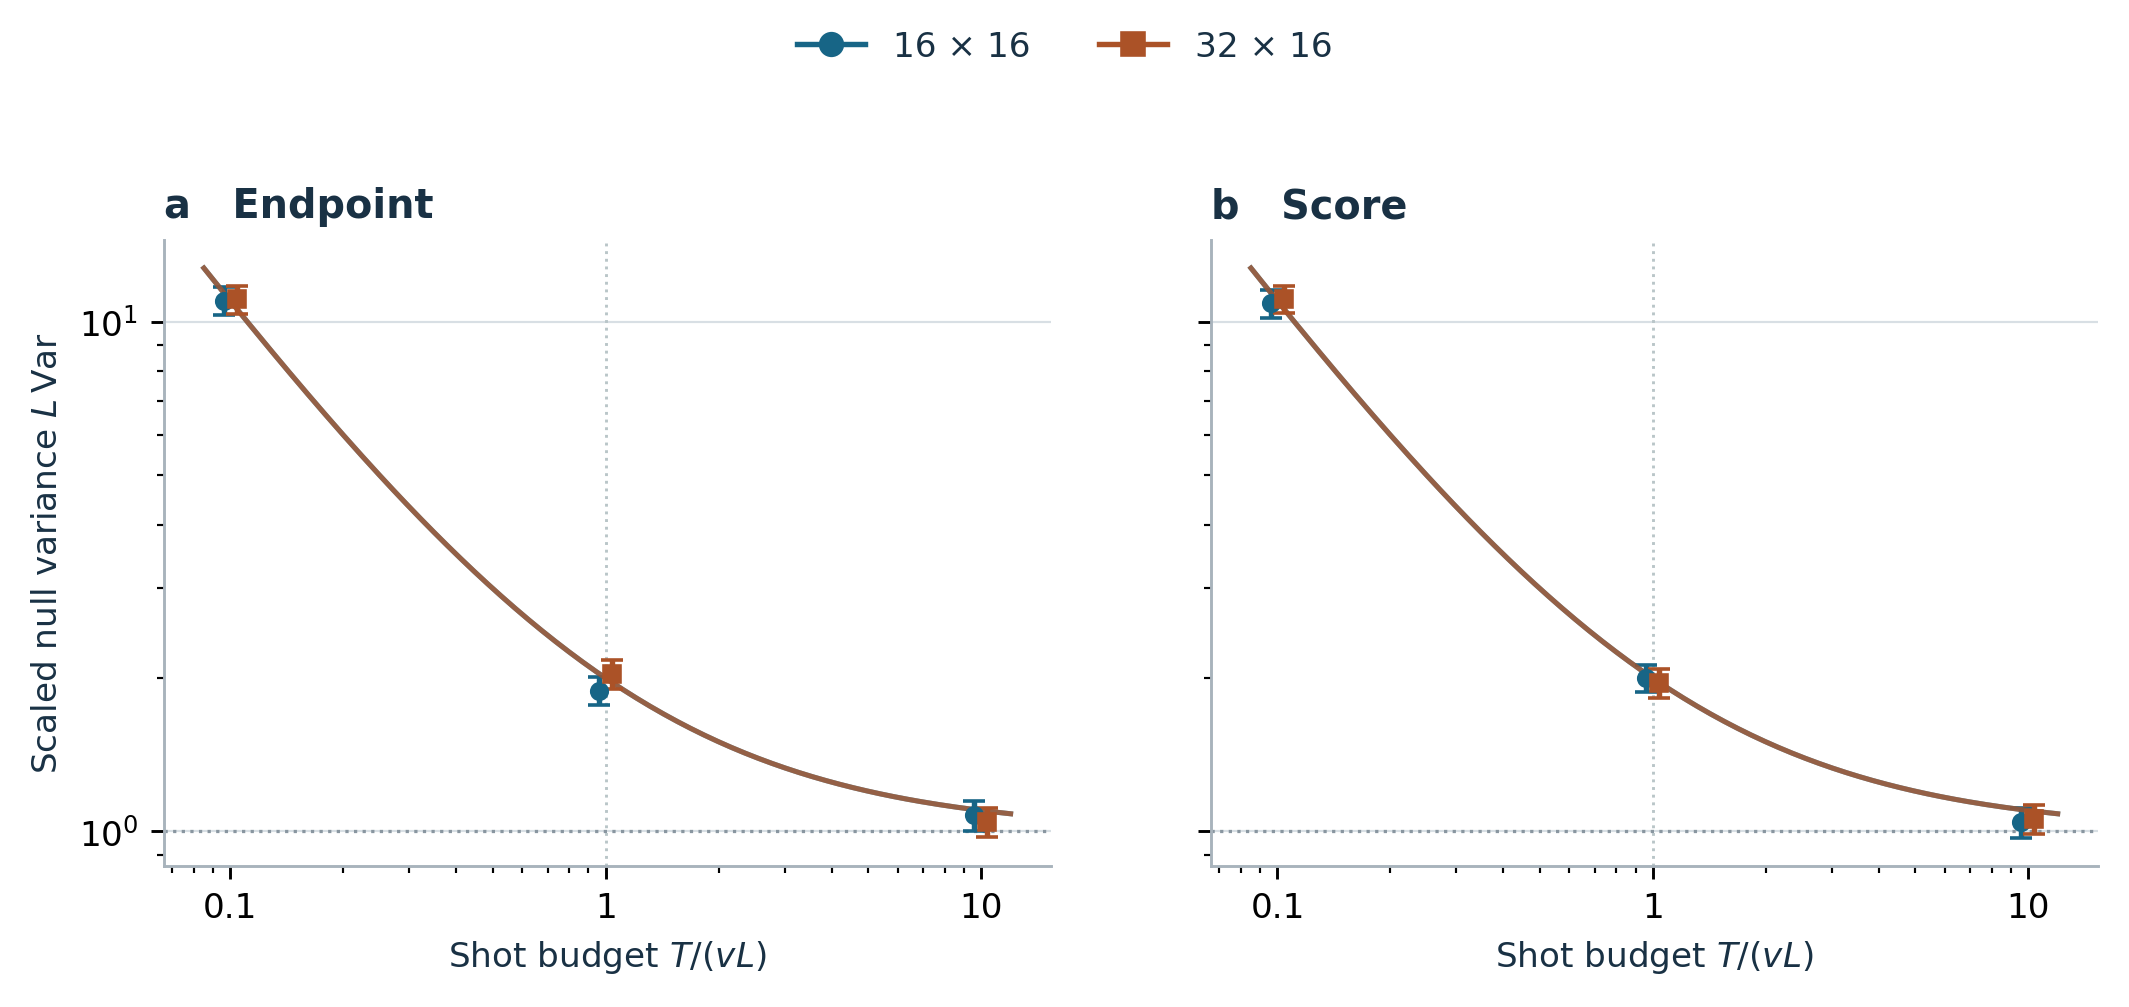

In [ ]:
display(Image(filename=str(RESULTS / "figures/04_shot_budget.png"), width=930))

### Conditional coverage on a fixed network
The target is the distinct-rectangle average on a single retained array. The exact column sums the binomial probabilities of counts for which the equal-tailed 95% interval covers this target. The archived arrays and repeated counts can be inspected directly.

In [ ]:
conditional = pd.read_csv(RESULTS / "tables/network_conditional_coverage.csv")
fixed = conditional[(conditional.m == focus) & (conditional.n == focus) &
                    (conditional.budget_for == "Score") & (conditional.budget_ratio == 1)]
display(fixed[["model", "delta", "U_C", "T", "rate", "rate_mcse", "exact_coverage"]]
        .rename(columns={"rate":"empirical_coverage", "rate_mcse":"coverage_MCSE"}).round(5))

,model,delta,U_C,T,empirical_coverage,coverage_MCSE,exact_coverage
88,Null,0.00,0.00389,126439,0.9540,0.00468,0.95129
94,Interaction,0.25,0.01708,126439,0.9435,0.00516,0.95328
100,Interaction,0.50,0.02111,126439,0.9630,0.00422,0.95285
106,Interaction,0.75,0.22208,126439,0.9495,0.00490,0.95332
112,Row,0.25,0.00111,126439,0.9470,0.00501,0.95168
118,Row,0.50,0.10889,126439,0.9565,0.00456,0.95412
124,Row,0.75,0.37819,126439,0.9550,0.00464,0.95243


### Finite-system and limiting moments
Read the points against the solid finite-system means, then compare those means with the dotted asymptotic levels. The row-only model has a nonzero row-degree function, so its eighth moment uses the full pairing formula.

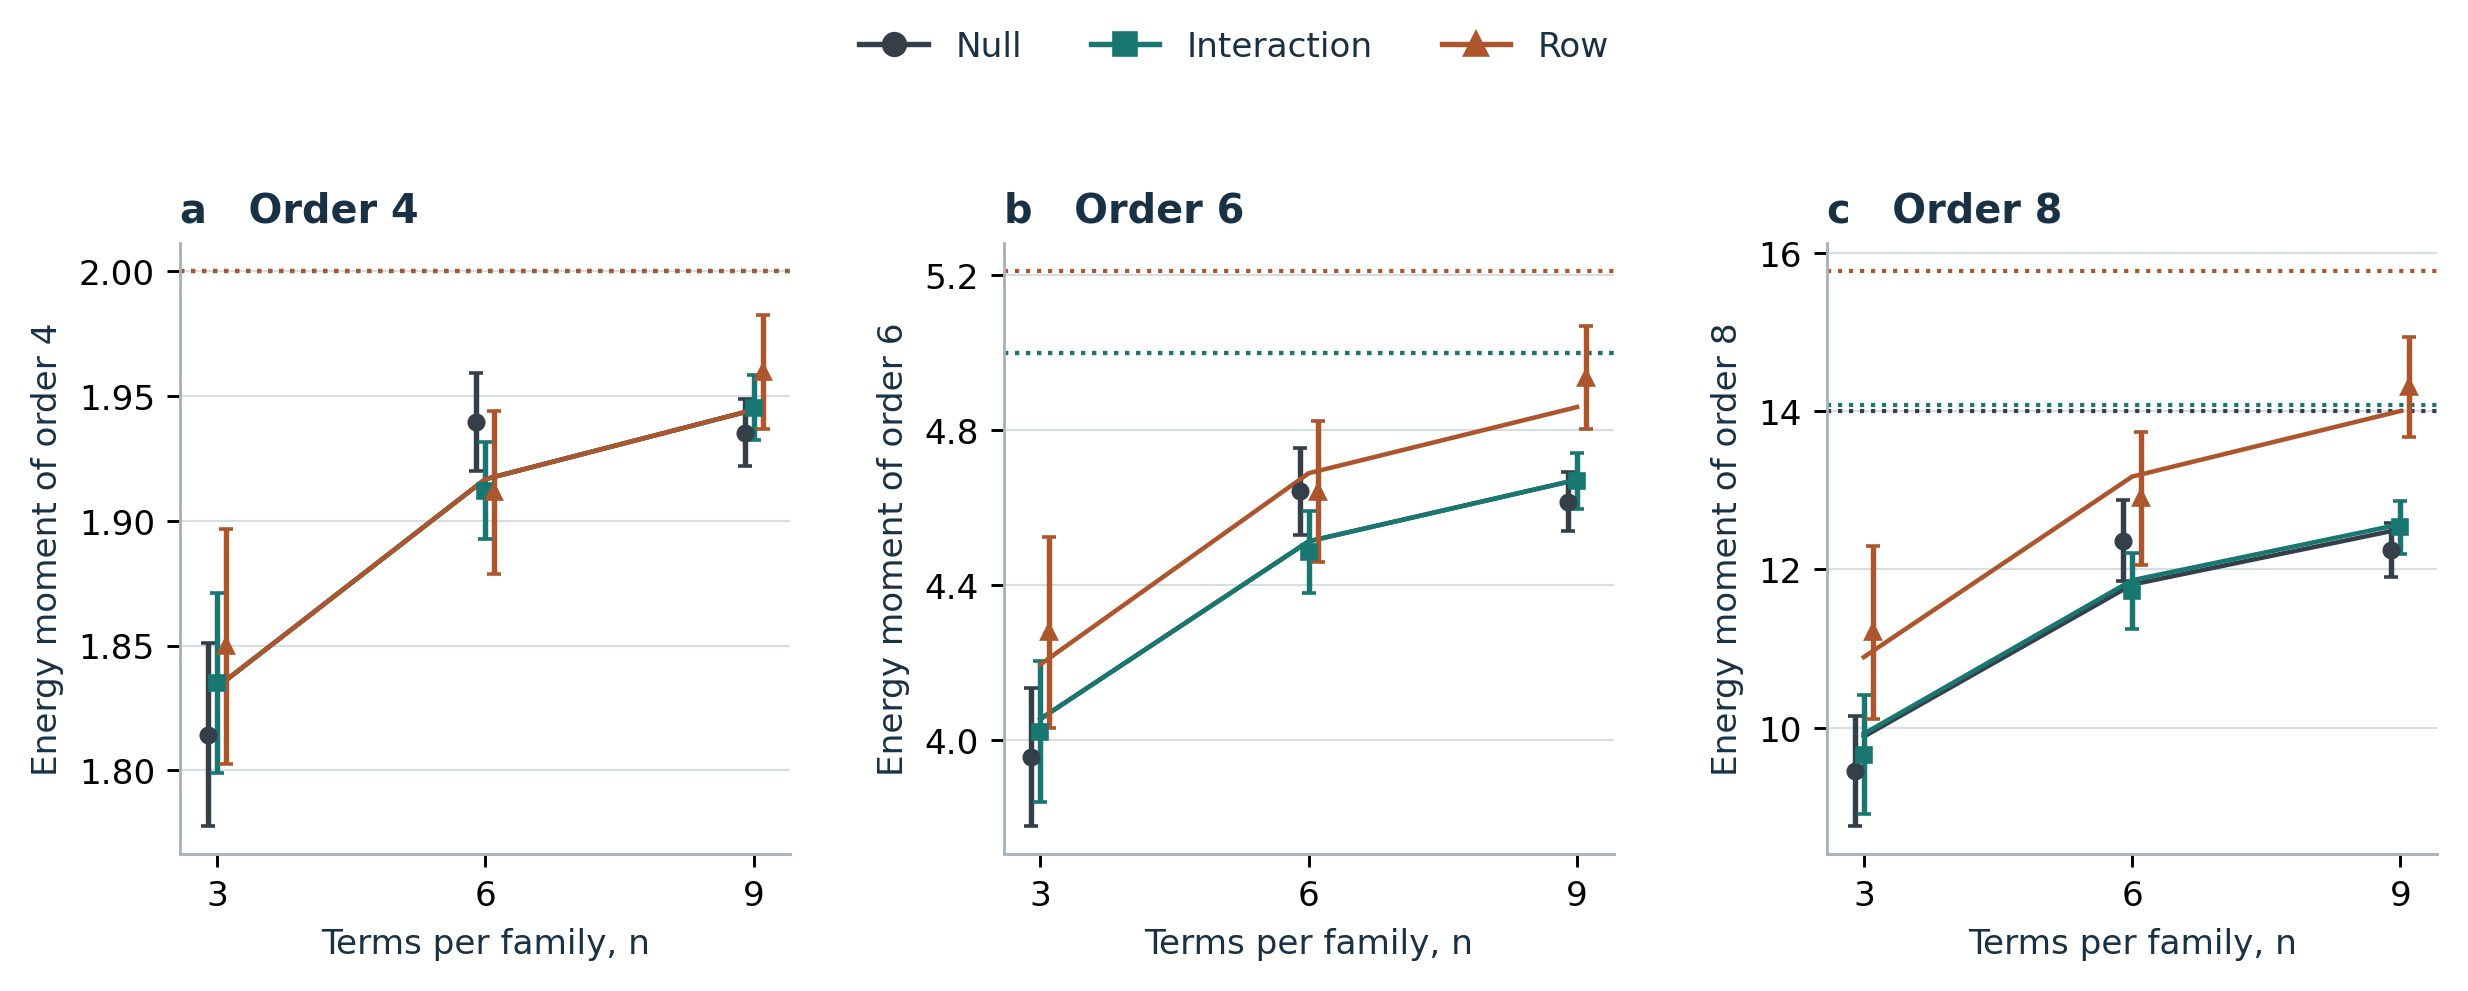

,model,order,mean,bias_mcse,finite_target,limit,finite_minus_limit
84,Null,4,1.93528,0.00686,1.94444,2.00000,-0.05556
85,Null,6,4.61635,0.03877,4.67284,5.00000,-0.32716
86,Null,8,12.24574,0.17143,12.50823,14.00000,-1.49177
93,Interaction,4,1.94531,0.00665,1.94444,2.00000,-0.05556
94,Interaction,6,4.66966,0.03736,4.67284,5.00000,-0.32716
95,Interaction,8,12.53212,0.16905,12.57073,14.07910,-1.50837
102,Row,4,1.95949,0.01165,1.94444,2.00000,-0.05556
103,Row,6,4.93583,0.06762,4.86034,5.21094,-0.35060
104,Row,8,14.30924,0.32284,14.00129,15.76660,-1.76532


In [ ]:
display(Image(filename=str(RESULTS / "figures/03_untagged_moments.png"), width=930))
moments = pd.read_csv(RESULTS / "tables/untagged_moments.csv")
view = moments[(moments.m == moments.n) & (moments.n == moments.n.max()) & (moments.delta.isin([0,.75]))]
display(view[["model","order","mean","bias_mcse","finite_target","limit","finite_minus_limit"]].round(5))

## 6. Download the return archive

Bring **Four_Cycle_Results.zip** back to the conversation for the empirical results and manuscript revision. It includes the full numerical tables, plotted values, replicate arrays, figure captions, source snapshot and run settings. The quick profile writes a separately named diagnostic ZIP.

In [ ]:
print(f"Results file: {ARCHIVE} ({ARCHIVE.stat().st_size/2**20:.1f} MiB)")
if DOWNLOAD_ON_FINISH:
    try:
        from google.colab import files
    except ImportError:
        display(FileLink(os.path.relpath(ARCHIVE, BASE)))
    else:
        files.download(str(ARCHIVE))
else:
    display(FileLink(os.path.relpath(ARCHIVE, BASE)))

Results file: /content/four_cycle_run_e2v4i5pk/Four_Cycle_Results.zip (11.5 MiB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>